# 🏙️ Mancha urbana con Sentinel-2 — demostración en Google Colab

**Clasificación de área construida (*built-up*) con un Random Forest entrenado con etiquetas automáticas**

Este cuaderno corre de principio a fin en Colab, **sin cuentas ni claves**: las imágenes vienen del catálogo abierto *Earth Search* (AWS) y las huellas de edificios del conjunto abierto *Overture Maps*, que en Centroamérica integra los edificios de Google Open Buildings.

| Paso | Qué hace |
|---|---|
| 1 | Instala y carga las librerías |
| 2 | Elige la ciudad (lista, catálogo o coordenadas), el tamaño del círculo y el periodo |
| 3 | Busca escenas Sentinel-2 L2A con pocas nubes |
| 4 | Enmascara nubes y arma un compuesto (mediana) |
| 5 | Calcula índices espectrales y variables de agua |
| 6 | Genera etiquetas de entrenamiento a partir de edificios **y calles** |
| 7 | Entrena un Random Forest (con hiperparámetros ajustables) y revisa su exactitud |
| 8 | Predice la probabilidad de área construida en toda la zona |
| 9 | Explora el resultado en un mapa interactivo |
| 10 | Resume superficies y descarga los rásteres y el bloque de variables |

**Cómo usarlo:** ejecuta las celdas en orden con ▶ (o `Ctrl/Cmd + Enter`). Con la zona por defecto el cuaderno completo tarda entre 5 y 10 minutos.

> 💡 Antes de empezar, guarda tu propia copia: **Archivo → Guardar una copia en Drive**. Así puedes modificar parámetros sin afectar el original.

## 1. Instalación

Colab ya trae `numpy`, `pandas`, `geopandas`, `scikit-learn`, `matplotlib` y `folium`. Solo falta instalar las librerías para leer el catálogo STAC, cargar las imágenes y descargar los edificios.

In [ ]:
%%capture
!pip install -q pystac-client odc-stac rioxarray overturemaps

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import folium
import rioxarray  # noqa: F401  (activa el accesor .rio)

from pystac_client import Client
import odc.stac
from rasterio.features import rasterize
from rasterio.transform import Affine
from scipy.ndimage import binary_dilation
from shapely.geometry import box
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})

import psutil
def ram(etapa=""):
    """Muestra cuánta memoria RAM usa la sesión de Colab."""
    v = psutil.virtual_memory()
    usada, total = (v.total - v.available) / 1e9, v.total / 1e9
    barra = "█" * round(20 * usada / total) + "░" * (20 - round(20 * usada / total))
    aviso = "  ⚠️ cerca del límite" if usada / total > 0.8 else ""
    print(f"🧠 RAM {etapa}: {barra} {usada:.1f} de {total:.1f} GB ({100 * usada / total:.0f} %){aviso}")
print("Librerías listas ✔")

Librerías listas ✔


## 2. Zona de estudio y periodo

La zona de estudio es un **círculo** alrededor del centro de una ciudad. Hay tres formas de elegirla:

1. **Lista de ciudades principales** (recomendado): 75 ciudades de Centroamérica y República Dominicana con el centro ya guardado. Solo elige una en `CIUDAD`.
2. **Buscar en el catálogo**: elige *"➕ Otra: buscar por nombre en el catálogo"* y escribe el nombre en `BUSCAR`. El catálogo tiene **779 ciudades y pueblos** de más de 5 000 habitantes (fuente: GeoNames). Si el nombre se repite en varios países, agrega el país: `San Miguel, El Salvador`. No importan las tildes ni las mayúsculas.
3. **Coordenadas manuales**: elige *"📍 Otra: coordenadas manuales"* y pega `LATITUD` y `LONGITUD` (en Google Maps: clic derecho sobre el mapa → clic en las coordenadas para copiarlas).

¿No sabes qué buscar? Corre la celda opcional **"Ver todas las ciudades del catálogo"** (después de los parámetros): muestra un mapa con todas, y al hacer clic en cada punto ves su nombre y coordenadas.

**Tamaño del círculo:** el radio va de 1 a **15 km** (de 3 a 707 km²).
- Hasta **8 km** (unos 200 km²) es lo seguro para Colab gratuito con muchos participantes a la vez.
- Por encima es **experimental**. La celda estima la memoria que va a necesitar y la compara con la RAM de tu sesión. Después, los pasos pesados muestran una línea **🧠 RAM** con el consumo real.
- Lo que más memoria pide es el compuesto del paso 4, que crece con el **área × el número de fechas**. Si Colab se reinicia por falta de memoria, baja `MAX_FECHAS` antes de achicar el radio.
- Con radios grandes también tardan más las descargas, y el GeoTIFF de variables pesa más (unos 50 MB por cada 100 km²).
- En las ciudades grandes (Guatemala, Santo Domingo, San Salvador) un círculo de 8 km cubre el centro, no toda el área metropolitana.

**Recomendaciones para la sesión:**
- En Centroamérica, el periodo **enero–abril** (estación seca) tiene menos nubes. En República Dominicana conviene probar **diciembre–marzo**.
- `MAX_FECHAS` controla cuántas fechas entran a la mediana: más fechas, compuesto más limpio pero más lento.


In [ ]:
#@title Catálogo de ciudades (ejecutar sin modificar) { display-mode: "form" }
import io, unicodedata, difflib

# Ciudades principales: centro de la ciudad (latitud, longitud)
CIUDADES_PRINCIPALES = {
    "Honduras · Tegucigalpa": (14.0825, -87.215),
    "Honduras · San Pedro Sula": (15.50585, -88.02588),
    "Honduras · La Ceiba": (15.75971, -86.78221),
    "Honduras · Choloma": (15.61444, -87.95302),
    "Honduras · El Progreso": (15.4, -87.8),
    "Honduras · Puerto Cortés": (15.82562, -87.92968),
    "Honduras · Choluteca": (13.30569, -87.17882),
    "Honduras · Comayagua": (14.45577, -87.63968),
    "Honduras · Danlí": (14.03333, -86.58333),
    "Honduras · Siguatepeque": (14.59691, -87.83102),
    "Honduras · Juticalpa": (14.66438, -86.22246),
    "Honduras · Santa Rosa de Copán": (14.77388, -88.7756),
    "Honduras · Tela": (15.77425, -87.46731),
    "Honduras · Roatán (Coxen Hole)": (16.31553, -86.53966),
    "Guatemala · Ciudad de Guatemala": (14.64072, -90.51327),
    "Guatemala · Mixco": (14.63077, -90.60711),
    "Guatemala · Villa Nueva": (14.52512, -90.58544),
    "Guatemala · Quetzaltenango": (14.84462, -91.52316),
    "Guatemala · Antigua Guatemala": (14.55636, -90.7332),
    "Guatemala · Escuintla": (14.30097, -90.78816),
    "Guatemala · Cobán": (15.47025, -90.37455),
    "Guatemala · Huehuetenango": (15.32097, -91.47001),
    "Guatemala · Chiquimula": (14.8009, -89.54641),
    "Guatemala · Puerto Barrios": (15.72724, -88.59787),
    "Guatemala · Flores (Petén)": (16.92258, -89.89941),
    "El Salvador · San Salvador": (13.68935, -89.18718),
    "El Salvador · Soyapango": (13.71024, -89.13989),
    "El Salvador · Santa Tecla": (13.67741, -89.28335),
    "El Salvador · Santa Ana": (13.98827, -89.55685),
    "El Salvador · San Miguel": (13.48261, -88.18211),
    "El Salvador · Sonsonate": (13.71726, -89.72304),
    "El Salvador · Usulután": (13.34467, -88.43994),
    "El Salvador · Ahuachapán": (13.92403, -89.84344),
    "El Salvador · La Unión": (13.33915, -87.84328),
    "Nicaragua · Managua": (12.13282, -86.2504),
    "Nicaragua · León": (12.43527, -86.87862),
    "Nicaragua · Masaya": (11.97316, -86.09587),
    "Nicaragua · Granada": (11.93062, -85.95368),
    "Nicaragua · Chinandega": (12.62951, -87.13133),
    "Nicaragua · Matagalpa": (12.92795, -85.91906),
    "Nicaragua · Estelí": (13.09291, -86.35589),
    "Nicaragua · Jinotega": (13.09103, -86.00234),
    "Nicaragua · Bluefields": (12.01292, -83.76449),
    "Nicaragua · Puerto Cabezas (Bilwi)": (14.03507, -83.38882),
    "Costa Rica · San José": (9.93388, -84.08489),
    "Costa Rica · Alajuela": (10.01723, -84.21275),
    "Costa Rica · Heredia": (9.99872, -84.11587),
    "Costa Rica · Cartago": (9.86371, -83.9195),
    "Costa Rica · Liberia": (10.63517, -85.43779),
    "Costa Rica · Puntarenas": (9.97691, -84.8379),
    "Costa Rica · Limón": (9.99074, -83.03596),
    "Costa Rica · San Isidro de El General": (9.3674, -83.69713),
    "Panamá · Ciudad de Panamá": (8.9936, -79.51973),
    "Panamá · San Miguelito": (9.05032, -79.47068),
    "Panamá · Arraiján": (8.9398, -79.64038),
    "Panamá · La Chorrera": (8.87763, -79.78007),
    "Panamá · Colón": (9.36025, -79.90019),
    "Panamá · David": (8.42729, -82.43085),
    "Panamá · Santiago de Veraguas": (8.1, -80.98333),
    "Panamá · Chitré": (7.96011, -80.42876),
    "Belice · Ciudad de Belice": (17.49952, -88.19756),
    "Belice · Belmopan": (17.25376, -88.76401),
    "Belice · San Ignacio": (17.1588, -89.0696),
    "Belice · Orange Walk": (18.08124, -88.56328),
    "República Dominicana · Santo Domingo": (18.47186, -69.89232),
    "República Dominicana · Santo Domingo Este": (18.48511, -69.84757),
    "República Dominicana · Santiago de los Caballeros": (19.45036, -70.69085),
    "República Dominicana · San Cristóbal": (18.41713, -70.10682),
    "República Dominicana · La Romana": (18.42332, -68.96635),
    "República Dominicana · San Pedro de Macorís": (18.4539, -69.30864),
    "República Dominicana · Puerto Plata": (19.79344, -70.6884),
    "República Dominicana · San Francisco de Macorís": (19.29377, -70.25285),
    "República Dominicana · La Vega": (19.22031, -70.53101),
    "República Dominicana · Higüey": (18.61501, -68.70798),
    "República Dominicana · Punta Cana": (18.58182, -68.40431),
}

# Catálogo completo: ciudades y pueblos de más de 5 000 habitantes (GeoNames, CC BY 4.0)
_CATALOGO_CSV = """pais;ciudad;poblacion;lat;lon
Belice;Ciudad de Belice;65222;17.49952;-88.19756
Belice;San Ignacio;21229;17.15880;-89.06960
Belice;San Pedro;17429;17.91598;-87.96590
Belice;Orange Walk;15298;18.08124;-88.56328
Belice;Belmopan;13381;17.25376;-88.76401
Belice;Dangriga;9927;16.96970;-88.23313
Belice;Corozal;9815;18.39375;-88.38849
Belice;Santa Elena;8587;17.16142;-89.05462
Belice;Ladyville;7655;17.55427;-88.29000
Belice;Benque Viejo el Carmen;7160;17.07500;-89.13917
Belice;Bella Vista;6259;16.50948;-88.53169
Belice;Trial Farm;5850;18.10124;-88.56584
Belice;Punta Gorda;5406;16.09835;-88.80970
Costa Rica;San José;335007;9.93388;-84.08489
Costa Rica;Limón;63081;9.99074;-83.03596
Costa Rica;San Francisco;55923;9.99380;-84.12742
Costa Rica;Alajuela;47494;10.01723;-84.21275
Costa Rica;Liberia;45380;10.63517;-85.43779
Costa Rica;Paraíso;39702;9.83847;-83.86655
Costa Rica;Puntarenas;35650;9.97691;-84.83790
Costa Rica;San Isidro;34877;9.36740;-83.69713
Costa Rica;Curridabat;34586;9.91390;-84.03595
Costa Rica;San Vicente;34447;9.96194;-84.04940
Costa Rica;San Vicente de Moravia;34447;9.96164;-84.04880
Costa Rica;Purral;30034;9.95689;-84.03209
Costa Rica;Turrialba;28955;9.90371;-83.68361
Costa Rica;San Miguel;28827;9.87121;-84.06084
Costa Rica;San Pedro;27477;9.92829;-84.05074
Costa Rica;San Rafael Abajo;27419;9.83100;-84.29008
Costa Rica;Quesada;27310;10.32660;-84.43200
Costa Rica;Ipís;26669;9.96548;-84.01820
Costa Rica;Cartago;26594;9.86371;-83.91950
Costa Rica;Chacarita;26354;9.98424;-84.77892
Costa Rica;San Juan;26047;9.96188;-84.07876
Costa Rica;Mercedes Norte;26007;10.00611;-84.13018
Costa Rica;Guadalupe;26005;9.94805;-84.05665
Costa Rica;Aserrí;25874;9.86142;-84.09266
Costa Rica;San Rafael;25410;9.92826;-84.13537
Costa Rica;San Felipe;24985;9.90444;-84.10620
Costa Rica;Patarrá;23983;9.88059;-84.03551
Costa Rica;Tejar;22433;9.74301;-84.23219
Costa Rica;Heredia;21947;9.99872;-84.11587
Costa Rica;San Pablo;21662;9.99559;-84.09656
Costa Rica;Calle Blancos;20710;9.94530;-84.06690
Costa Rica;Cañas;20306;10.43105;-85.09825
Costa Rica;Guápiles;19092;10.21682;-83.78483
Costa Rica;Siquirres;18231;10.09748;-83.50659
Costa Rica;San Diego;16991;9.90028;-84.00170
Costa Rica;Colima;15875;9.95532;-84.08235
Costa Rica;Esparza;15575;9.99197;-84.66628
Costa Rica;San Juan de Dios;15469;9.87812;-84.08438
Costa Rica;Nicoya;15313;10.15038;-85.45093
Costa Rica;San Rafael Arriba;15051;9.87648;-84.07479
Costa Rica;Desamparados;14448;9.94727;-84.50626
Costa Rica;Concepción;14000;9.92683;-84.00123
Costa Rica;Alajuelita;13845;9.90294;-84.10037
Costa Rica;Sabanilla;13251;9.94706;-84.03408
Costa Rica;Granadilla;12683;9.93203;-84.01964
Costa Rica;Santa Cruz;12281;10.26053;-85.58510
Costa Rica;San Josecito;12195;10.01265;-84.10750
Costa Rica;Escazú;12071;9.91887;-84.13989
Costa Rica;Naranjo;11853;10.09866;-84.37824
Costa Rica;Buenos Aires;11680;9.17298;-83.33277
Costa Rica;San Antonio;10938;9.98160;-84.18592
Costa Rica;San Ramón;10765;10.08802;-84.47022
Costa Rica;Tres Ríos;10430;9.90692;-83.98789
Costa Rica;Daniel Flores;10028;9.33607;-83.66999
Costa Rica;Río Segundo;9853;10.23980;-84.31710
Costa Rica;Colón;9687;9.91491;-84.24170
Costa Rica;Santiago;8292;9.84636;-84.31428
Costa Rica;Santa Ana;8029;9.93260;-84.18255
Costa Rica;Quepos;7810;9.43063;-84.16231
Costa Rica;Tilarán;7301;10.46701;-84.96775
Costa Rica;Corredor;7084;8.64002;-82.94600
Costa Rica;Guácimo;7022;10.21290;-83.68793
Costa Rica;Atenas;7014;9.97489;-84.37886
Costa Rica;Cot;6784;9.89472;-83.87450
Costa Rica;Golfito;6777;8.60327;-83.11342
Costa Rica;Llorente;6626;9.99842;-84.15814
Costa Rica;Miramar;6540;10.09250;-84.72978
Costa Rica;Tamarindo;6375;10.29913;-85.84107
Costa Rica;Orotina;6135;9.91193;-84.52337
Costa Rica;Santo Domingo;5745;10.06389;-84.15499
Costa Rica;Salitrillos;5738;9.85373;-84.09160
Costa Rica;Mercedes;5467;9.27447;-83.57968
Costa Rica;Pocora;5248;10.17195;-83.60264
El Salvador;San Salvador;525990;13.68935;-89.18718
El Salvador;Soyapango;329708;13.71024;-89.13989
El Salvador;San Miguel;247126;13.48261;-88.18211
El Salvador;Santa Ana;176661;13.98827;-89.55685
El Salvador;Mejicanos;160317;13.72397;-89.18800
El Salvador;Santa Tecla;124694;13.67741;-89.28335
El Salvador;Apopa;112158;13.80722;-89.17917
El Salvador;Ciudad Delgado;71594;13.72171;-89.16874
El Salvador;Sonsonate;59468;13.71726;-89.72304
El Salvador;San Marcos;54615;13.66108;-89.18252
El Salvador;Usulután;51910;13.34467;-88.43994
El Salvador;Cojutepeque;48411;13.71971;-88.93309
El Salvador;Cuscatancingo;44369;13.72702;-89.18161
El Salvador;San Vicente;41504;13.64114;-88.78459
El Salvador;Zacatecoluca;39613;13.50872;-88.87017
El Salvador;San Martín;39361;13.78333;-88.91667
El Salvador;Ilopango;38890;13.70167;-89.10944
El Salvador;Ahuachapán;34102;13.92403;-89.84344
El Salvador;Antiguo Cuscatlán;33767;13.66492;-89.25319
El Salvador;Chalchuapa;32282;13.98667;-89.68111
El Salvador;Quezaltepeque;28886;13.83124;-89.27221
El Salvador;La Unión;26807;13.33915;-87.84328
El Salvador;Ayutuxtepeque;25426;13.73538;-89.20221
El Salvador;Acajutla;22763;13.59278;-89.82750
El Salvador;Aguilares;21445;13.95722;-89.18972
El Salvador;Sensuntepeque;20386;13.87583;-88.62727
El Salvador;Chalatenango;19364;14.04138;-88.93951
El Salvador;Izalco;19197;13.74472;-89.67306
El Salvador;Metapán;19143;14.33333;-89.45000
El Salvador;San Rafael Oriente;19095;13.38333;-88.35000
El Salvador;Puerto El Triunfo;19074;13.28333;-88.55000
El Salvador;La Libertad;16855;13.48833;-89.32222
El Salvador;San Francisco;16152;13.69408;-88.10407
El Salvador;Sonzacate;15446;13.73417;-89.71472
El Salvador;Santiago de María;15032;13.48333;-88.46667
El Salvador;Armenia;14997;13.74361;-89.49889
El Salvador;Santo Tomás;14581;13.64083;-89.13333
El Salvador;Santa Rosa de Lima;13249;13.62472;-87.89361
El Salvador;Turín;11829;13.96639;-89.76611
El Salvador;Zaragoza;11749;13.58944;-89.28889
El Salvador;Berlín;11313;13.50000;-88.53333
El Salvador;Guazapa;10995;13.87694;-89.17306
El Salvador;Jucuapa;10601;13.51667;-88.38333
El Salvador;Ciudad Arce;10095;13.84028;-89.44722
El Salvador;Nueva Concepción;9990;14.13333;-89.30000
El Salvador;Juayúa;9936;13.84139;-89.74556
El Salvador;Santiago Nonualco;9490;13.51667;-88.95000
El Salvador;El Tránsito;9485;13.35000;-88.35000
El Salvador;Atiquizaya;9476;13.97694;-89.75250
El Salvador;San Antonio del Monte;9135;13.71639;-89.73833
El Salvador;Jiquilisco;9129;13.31667;-88.58333
El Salvador;El Congo;8905;13.90889;-89.49583
El Salvador;Chinameca;8646;13.50000;-88.35000
El Salvador;Ciudad Barrios;8491;13.76667;-88.26667
El Salvador;Concepción de Ataco;7797;13.87028;-89.84861
El Salvador;Nahuizalco;7358;13.77750;-89.73667
El Salvador;San Sebastián;7333;13.73333;-88.83333
El Salvador;San Juan Opico;7127;13.87611;-89.35972
El Salvador;Panchimalco;6764;13.61278;-89.18000
El Salvador;Nuevo Cuscatlán;6469;13.64861;-89.26528
El Salvador;Chirilagua;6393;13.22028;-88.13861
El Salvador;Olocuilta;6324;13.56972;-89.11722
El Salvador;Candelaria de La Frontera;6301;14.11667;-89.65000
El Salvador;Tonacatepeque;6245;13.78111;-89.11861
El Salvador;Santa Elena;5887;13.38333;-88.41667
El Salvador;Nueva Guadalupe;5798;13.53333;-88.35000
El Salvador;Apastepeque;5785;13.66667;-88.78333
El Salvador;Coatepeque;5773;13.92861;-89.50417
El Salvador;Suchitoto;5735;13.93806;-89.02778
El Salvador;El Rosario;5620;13.49778;-89.02972
El Salvador;Guatajiagua;5273;13.66667;-88.20000
El Salvador;Rosario de Mora;5178;13.57528;-89.20889
El Salvador;San Alejo;5149;13.43139;-87.96306
El Salvador;Tacuba;5055;13.90111;-89.92972
Guatemala;Ciudad de Guatemala;994938;14.64072;-90.51327
Guatemala;Villa Nueva;618397;14.52512;-90.58544
Guatemala;Mixco;465773;14.63077;-90.60711
Guatemala;Cobán;212047;15.47025;-90.37455
Guatemala;Quetzaltenango;180706;14.84462;-91.52316
Guatemala;Jalapa;159840;14.63542;-89.99112
Guatemala;Escuintla;156313;14.30097;-90.78816
Guatemala;Villa Canales;155423;14.48285;-90.53425
Guatemala;Jutiapa;145880;14.28491;-89.88798
Guatemala;Chichicastenango;141567;14.94333;-91.11116
Guatemala;San Juan Sacatepéquez;136886;14.71889;-90.64417
Guatemala;San Miguel Petapa;135447;14.50189;-90.56196
Guatemala;Santa Lucía Cotzumalguapa;112780;14.33505;-91.02339
Guatemala;Chiquimula;111505;14.80090;-89.54641
Guatemala;Coatepeque;105415;14.70413;-91.86426
Guatemala;Chinautla;104972;14.70289;-90.49983
Guatemala;Totonicapán;103952;14.91188;-91.36054
Guatemala;Puerto Barrios;100593;15.72724;-88.59787
Guatemala;Chimaltenango;96985;14.65881;-90.82160
Guatemala;Malacatán;92816;14.91132;-92.05788
Guatemala;Retalhuleu;90505;14.53575;-91.67848
Guatemala;Santa Catarina Pinula;80582;14.57047;-90.49925
Guatemala;San José Pinula;79844;14.54600;-90.41288
Guatemala;Huehuetenango;79426;15.32097;-91.47001
Guatemala;Santa Cruz del Quiché;78279;15.02995;-91.14876
Guatemala;Mazatenango;77431;14.53412;-91.50311
Guatemala;Panzos;71846;15.39862;-89.64147
Guatemala;Amatitlán;71836;14.47740;-90.63489
Guatemala;Palín;65873;14.40358;-90.69659
Guatemala;Salamá;65275;15.10210;-90.31906
Guatemala;Chicacao;60735;14.54295;-91.32636
Guatemala;Zacapa;60424;14.96867;-89.52732
Guatemala;Comitancillo;59489;15.08937;-91.74971
Guatemala;Fraijanes;58922;14.46528;-90.44083
Guatemala;San Pedro Ayampuc;58609;14.77943;-90.45318
Guatemala;Patzún;58240;14.68189;-91.01397
Guatemala;San Francisco El Alto;57894;14.94490;-91.44310
Guatemala;Ostuncalco;51828;14.86899;-91.62137
Guatemala;Soloma;49030;15.65841;-91.42994
Guatemala;Asunción Mita;48297;14.33365;-89.71094
Guatemala;Colomba;47544;14.70730;-91.73167
Guatemala;Barberena;47093;14.30739;-90.36156
Guatemala;San Marcos;47063;14.96437;-91.79486
Guatemala;Antigua Guatemala;46054;14.55636;-90.73320
Guatemala;Sololá;45373;14.77070;-91.18344
Guatemala;Masagua;45323;14.20306;-90.84806
Guatemala;Cantel;42142;14.81154;-91.45536
Guatemala;Cuilapa;41359;14.27537;-90.29865
Guatemala;Patulul;40683;14.42321;-91.16049
Guatemala;San Pedro Sacatepéquez;40021;14.96807;-91.76172
Guatemala;Nuevo San Carlos;39565;14.59300;-91.69390
Guatemala;Jacaltenango;37171;15.66662;-91.71177
Guatemala;Yepocapa;34948;14.50195;-90.95396
Guatemala;Tecpán Guatemala;34519;14.76181;-90.99247
Guatemala;Ciudad Vieja;33405;14.52396;-90.76308
Guatemala;Santiago Atitlán;33309;14.63823;-91.22901
Guatemala;Comalapa;32312;14.74086;-90.88761
Guatemala;Momostenango;31739;15.04437;-91.40864
Guatemala;San Benito;30764;16.91675;-89.91898
Guatemala;Santiago Sacatepéquez;29238;14.63510;-90.67654
Guatemala;San Sebastián;29167;14.56177;-91.64865
Guatemala;Jalpatagua;28832;14.13690;-90.00908
Guatemala;Sumpango;28488;14.64623;-90.73427
Guatemala;Nahualá;27690;14.84290;-91.31799
Guatemala;San Andrés Itzapa;24992;14.62222;-90.84314
Guatemala;Guastatoya;24831;14.85442;-90.06991
Guatemala;San Luis Jilotepeque;24679;14.64724;-89.72463
Guatemala;San Felipe;24446;14.62304;-91.59500
Guatemala;Zaragoza;24022;14.64968;-90.89034
Guatemala;La Gomera;24001;14.08213;-91.05383
Guatemala;Alotenango;23986;14.48585;-90.80437
Guatemala;Nebaj;23301;15.40614;-91.14682
Guatemala;Cabricán;23033;15.07485;-91.64800
Guatemala;San Francisco Zapotitlán;22533;14.58939;-91.52144
Guatemala;Santa María de Jesús;21795;14.49452;-90.71036
Guatemala;Patzicía;21249;14.63194;-90.92659
Guatemala;San Lucas Sacatepéquez;20723;14.61075;-90.65681
Guatemala;Esquipulas;20674;14.56571;-89.35166
Guatemala;El Estor;20489;15.53221;-89.33111
Guatemala;Flores;20464;16.92258;-89.89941
Guatemala;San Pablo Jocopilas;20433;14.58882;-91.45188
Guatemala;San Cristóbal Verapaz;19664;15.36663;-90.47825
Guatemala;Salcajá;19434;14.87964;-91.45699
Guatemala;Gualán;19354;15.11952;-89.35721
Guatemala;Morales;18994;15.47225;-88.84070
Guatemala;Guazacapán;18855;14.07417;-90.41667
Guatemala;Puerto San José;18655;13.92216;-90.81906
Guatemala;Palencia;18574;14.66715;-90.35721
Guatemala;Tiquisate;18189;14.28356;-91.36063
Guatemala;Lívingston;17923;15.82826;-88.75039
Guatemala;Jocotenango;17918;14.57814;-90.73804
Guatemala;El Asintal;17388;14.59626;-91.72744
Guatemala;Poptún;17320;16.33111;-89.41694
Guatemala;Santa Bárbara;17172;14.43563;-91.22685
Guatemala;Chisec;17018;15.81311;-90.28896
Guatemala;La Esperanza;16461;14.87169;-91.56140
Guatemala;San Pedro Carchá;16353;15.47745;-90.31105
Guatemala;Sanarate;15843;14.78828;-90.19876
Guatemala;El Tejar;15639;14.64683;-90.79122
Guatemala;El Palmar;15167;14.65083;-91.57800
Guatemala;Rabinal;15157;15.08530;-90.49255
Guatemala;San Andrés Xecul;15074;14.90482;-91.48307
Guatemala;Santa Catarina Ixtahuacán;14734;14.79797;-91.35866
Guatemala;San Lucas Tolimán;14545;14.59471;-91.14659
Guatemala;Zunil;14118;14.78463;-91.48345
Guatemala;Barillas;14100;15.80361;-91.31583
Guatemala;San Miguel Chicaj;13747;15.09472;-90.39442
Guatemala;San Pablo;13668;14.93269;-92.00415
Guatemala;San Antonio Suchitepéquez;13666;14.53938;-91.41442
Guatemala;Monjas;13541;14.50309;-89.87246
Guatemala;La Democracia;13400;14.22919;-90.94806
Guatemala;San Juan Chamelco;13264;15.42433;-90.33044
Guatemala;San Mateo Ixtatán;13213;15.83194;-91.47806
Guatemala;Joyabaj;13164;14.99311;-90.80161
Guatemala;Chiquimulilla;12842;14.08380;-90.38547
Guatemala;Pastores;12621;14.59433;-90.75473
Guatemala;Almolonga;12299;14.81591;-91.49464
Guatemala;Santa Lucía Milpas Altas;12234;14.57655;-90.67632
Guatemala;Acatenango;12136;14.55451;-90.94368
Guatemala;El Quetzal;12122;14.76865;-91.81757
Guatemala;Sacapulas;12088;15.28801;-91.08914
Guatemala;Senahú;12084;15.41640;-89.82215
Guatemala;Flores Costa Cuca;11984;14.63238;-91.86341
Guatemala;Magdalena Milpas Altas;11856;14.54801;-90.67477
Guatemala;Chajul;11657;15.48523;-91.03520
Guatemala;Atescatempa;11543;14.17550;-89.74184
Guatemala;Melchor de Mencos;11457;17.06606;-89.15229
Guatemala;Ciudad Tecún Umán;11432;14.67737;-92.14039
Guatemala;Panajachel;11142;14.74185;-91.15676
Guatemala;Nueva Concepción;11121;14.20000;-91.30000
Guatemala;San Juan Cotzal;11046;15.43368;-91.03481
Guatemala;Cuyotenango;10825;14.54006;-91.57179
Guatemala;Santa Catarina Mita;10817;14.45131;-89.74285
Guatemala;Cubulco;10681;15.10452;-90.62871
Guatemala;Dolores;10604;16.51178;-89.41704
Guatemala;San Agustín Acasaguastlán;10335;14.94500;-89.96967
Guatemala;Oratorio;10155;14.22806;-90.17583
Guatemala;Nueva Santa Rosa;10130;14.38111;-90.27611
Guatemala;Nuevo León;10000;15.79369;-91.09237
Guatemala;Huitán;9958;15.04920;-91.63944
Guatemala;Champerico;9941;14.29206;-91.91339
Guatemala;San Martín Jilotepeque;9846;14.78008;-90.79259
Guatemala;San Pedro La Laguna;9681;14.69297;-91.27201
Guatemala;Parramos;9613;14.60891;-90.80303
Guatemala;Santa Ana;9523;16.80582;-89.82708
Guatemala;Zacualpa;9241;15.02681;-90.87815
Guatemala;San Cristóbal Cucho;9152;14.90505;-91.78123
Guatemala;Sayaxché;9100;16.52446;-90.18801
Guatemala;Tactic;8999;15.32218;-90.35448
Guatemala;Samayac;8994;14.58084;-91.46135
Guatemala;Estanzuela;8937;14.99777;-89.57285
Guatemala;Concepción Huista;8925;15.62378;-91.66521
Guatemala;El Tumbador;8856;14.86375;-91.93416
Guatemala;Santo Domingo Xenacoj;8791;14.68057;-90.70012
Guatemala;San Raimundo;8689;14.76462;-90.59493
Guatemala;La Libertad;8646;16.78850;-90.11698
Guatemala;Chiantla;8465;15.35484;-91.45807
Guatemala;San Miguel Dueñas;8424;14.52241;-90.79938
Guatemala;Cunén;8400;15.33626;-91.02776
Guatemala;Jocotán;8387;14.82072;-89.38991
Guatemala;Pajapita;8164;14.72152;-92.03521
Guatemala;Moyuta;8145;14.03861;-90.08083
Guatemala;Nuevo Progreso;8113;14.79174;-91.91946
Guatemala;San Jerónimo;8093;15.06032;-90.24050
Guatemala;Concepción Chiquirichapa;8080;14.85510;-91.62360
Guatemala;Santa Cruz Balanyá;7825;14.68522;-90.91906
Guatemala;San Antonio Aguas Calientes;7811;14.54676;-90.78054
Guatemala;San Antonio La Paz;7781;14.75888;-90.28485
Guatemala;Casillas;7698;14.41915;-90.24328
Guatemala;Río Bravo;7568;14.40042;-91.31713
Guatemala;San Miguel Sigüilá;7551;14.89547;-91.61457
Guatemala;Mataquescuintla;7539;14.52917;-90.18417
Guatemala;Chahal;7465;15.79122;-89.60518
Guatemala;El Progreso;7350;14.35604;-89.84854
Guatemala;San Andrés;7235;16.96863;-89.91181
Guatemala;San Vicente Pacaya;7162;14.41466;-90.63613
Guatemala;Chuarrancho;7149;14.81794;-90.51568
Guatemala;Santo Tomás La Unión;7081;14.63219;-91.41075
Guatemala;Santa María Chiquimula;6980;15.02992;-91.32920
Guatemala;San Carlos Sija;6831;14.98436;-91.54912
Guatemala;San Luis;6776;16.19889;-89.44028
Guatemala;Uspantán;6664;15.34672;-90.87050
Guatemala;Taxisco;6518;14.06719;-90.46791
Guatemala;Tacaná;6438;15.24058;-92.06721
Guatemala;Teculután;6407;14.98901;-89.71936
Guatemala;San José Acatempa;6367;14.26528;-90.12694
Guatemala;Santo Domingo Suchitepéquez;6270;14.47901;-91.48327
Guatemala;San Bartolomé Milpas Altas;6261;14.60690;-90.67807
Guatemala;Santa Cruz Naranjo;6254;14.38806;-90.36972
Guatemala;San Pablo La Laguna;6186;14.72092;-91.27242
Guatemala;Concepción Tutuapa;6006;15.23940;-91.84460
Guatemala;Río Hondo;5997;15.04505;-89.58523
Guatemala;San José Poaquil;5987;14.81808;-90.91248
Guatemala;Santa Rosa de Lima;5984;14.38806;-90.29556
Guatemala;Santa Cruz Verapaz;5843;15.37342;-90.42857
Guatemala;San Antonio Huista;5669;15.65010;-91.77163
Guatemala;Aguacatán;5572;15.34222;-91.31141
Guatemala;San Mateo;5534;14.85800;-91.59004
Guatemala;San Bernardino;5501;14.54240;-91.45811
Guatemala;Purulhá;5370;15.23566;-90.23571
Guatemala;Santa Clara La Laguna;5306;14.71509;-91.30355
Guatemala;Ipala;5283;14.61987;-89.61940
Guatemala;San Andrés Villa Seca;5102;14.57801;-91.58539
Honduras;Tegucigalpa;850848;14.08180;-87.20681
Honduras;San Pedro Sula;801259;15.50585;-88.02588
Honduras;Danlí;233789;14.03333;-86.58333
Honduras;La Ceiba;222055;15.75971;-86.78221
Honduras;Puerto Cortés;142311;15.82562;-87.92968
Honduras;Catacamas;140548;14.85114;-85.89412
Honduras;Choloma;139100;15.61444;-87.95302
Honduras;Siguatepeque;127468;14.59691;-87.83102
Honduras;Olanchito;124286;15.48131;-86.57415
Honduras;Tocoa;111972;15.68333;-86.00000
Honduras;El Progreso;100810;15.40000;-87.80000
Honduras;Santa Cruz de Yojoa;97848;14.98086;-87.89091
Honduras;Choluteca;75872;13.30569;-87.17882
Honduras;San Pedro de Copán;63829;14.61667;-88.86667
Honduras;Comayagua;58784;14.45577;-87.63968
Honduras;Omoa;58172;15.77603;-88.03833
Honduras;El Negrito;50550;15.31667;-87.70000
Honduras;Sonaguera;48087;15.63333;-86.33333
Honduras;Quimistán;47993;15.34752;-88.40520
Honduras;La Lima;45955;15.43333;-87.91667
Honduras;Teupasenti;43477;14.21667;-86.70000
Honduras;Lepaera;37876;14.77876;-88.59020
Honduras;Macuelizo;34401;15.31276;-88.54113
Honduras;Victoria;34215;14.93761;-87.39354
Honduras;Sabá;33879;15.46667;-86.25000
Honduras;Juticalpa;33686;14.66438;-86.22246
Honduras;Villa de San Antonio;32419;14.32594;-87.61351
Honduras;Villanueva;31571;15.31476;-87.99383
Honduras;Dulce Nombre de Culmí;30543;15.10000;-85.53333
Honduras;El Rosario;30042;14.57909;-87.72677
Honduras;Tela;29325;15.77425;-87.46731
Honduras;Santa Rosa de Copán;27753;14.77388;-88.77560
Honduras;Potrerillos;26954;15.23008;-87.96386
Honduras;La Iguala;26805;14.61667;-88.46667
Honduras;Arizona;25320;15.63333;-87.31667
Honduras;San Francisco de Yojoa;24740;15.01442;-87.97160
Honduras;Marcovia;24646;13.28806;-87.30972
Honduras;San Luis;24606;15.12692;-88.43931
Honduras;Sabanagrande;23943;13.80778;-87.25917
Honduras;San Antonio de Cortés;22884;15.11611;-88.04074
Honduras;Gualaco;22327;15.02521;-86.07076
Honduras;San Lorenzo;22289;13.42417;-87.44722
Honduras;Yamaranguila;21633;14.28333;-88.24199
Honduras;Santa Rita;21536;15.20000;-87.88333
Honduras;Iriona;21207;15.96777;-85.09323
Honduras;Esquías;21009;14.74392;-87.37120
Honduras;Langue;20944;13.62083;-87.65250
Honduras;Cofradía;20353;15.40000;-88.15000
Honduras;Azacualpa;20210;14.71218;-88.09010
Honduras;Yorito;19824;15.06667;-87.28333
Honduras;Corquín;19145;14.56667;-88.86667
Honduras;San José de Colinas;18791;15.04101;-88.30186
Honduras;El Paraíso;18779;13.86667;-86.55000
Honduras;Colomoncagua;18484;13.95000;-88.28333
Honduras;Sulaco;18161;14.91667;-87.26667
Honduras;Atima;17648;14.93253;-88.48965
Honduras;La Paz;17555;14.32124;-87.67589
Honduras;Morocelí;17153;14.11667;-86.86667
Honduras;Cucuyagua;16707;14.64777;-88.87385
Honduras;San Juan de Flores;16070;14.26667;-87.03333
Honduras;Belén Gualcho;15983;14.48333;-88.80000
Honduras;Yoro;15774;15.13824;-87.12838
Honduras;Erandique;15633;14.23787;-88.46447
Honduras;Santa Bárbara;15119;14.92217;-88.23756
Honduras;Guajiquiro;14959;14.11667;-87.83333
Honduras;La Entrada;14739;15.06381;-88.74627
Honduras;San Manuel de Colohete;14583;14.45000;-88.66667
Honduras;Limón;14421;15.86667;-85.50000
Honduras;Goascorán;14342;13.58333;-87.61667
Honduras;Piraera;14124;14.06667;-88.46667
Honduras;Nacaome;13929;13.53917;-87.48913
Honduras;Intibucá;13741;14.31226;-88.17608
Honduras;San Andrés;13585;14.21667;-88.55000
Honduras;Talanga;13492;14.40000;-87.08333
Honduras;Minas de Oro;13341;14.79611;-87.34654
Honduras;Brus Laguna;13224;15.75000;-84.48333
Honduras;Guayape;12907;14.71667;-86.83333
Honduras;Guaimaca;12899;14.53333;-86.81667
Honduras;Amapala;12743;13.29222;-87.65389
Honduras;Meámbar;12522;14.78333;-87.76667
Honduras;Yocón;12182;15.01667;-86.70000
Honduras;Petoa;12135;15.26939;-88.28878
Honduras;La Guata;12084;15.08333;-86.38333
Honduras;Sensenti;11668;14.49379;-88.93761
Honduras;Manto;11641;14.91667;-86.38333
Honduras;Gualcince;11564;14.11667;-88.55000
Honduras;Ajuterique;11356;14.38304;-87.70965
Honduras;Morazán;11076;15.31667;-87.60000
Honduras;San Sebastián;10857;14.25000;-88.50000
Honduras;Villa de San Francisco;10816;14.16667;-86.96667
Honduras;Esquipulas del Norte;10781;15.30000;-86.53333
Honduras;Santa María del Real;10767;14.76667;-85.95000
Honduras;Liure;10760;13.53583;-87.09194
Honduras;Talgua;10744;14.70000;-88.70000
Honduras;San Pedro Zacapa;10535;14.75650;-88.11373
Honduras;Marcala;10054;14.15661;-88.03466
Honduras;San Francisco del Valle;9839;14.43542;-88.95608
Honduras;La Labor;9838;14.48625;-89.00272
Honduras;San Francisco de Coray;9742;13.66139;-87.53278
Honduras;San Juan de Opoa;9709;14.77900;-88.69641
Honduras;Jocón;9659;15.28333;-86.96667
Honduras;Trujillo;9646;15.91741;-85.95263
Honduras;Alauca;9273;13.85000;-86.68333
Honduras;Baracoa;9202;15.77581;-87.85255
Honduras;Yarula;9185;14.11667;-88.08333
Honduras;San Francisco;9146;14.11667;-88.36667
Honduras;Sinuapa;9145;14.44305;-89.18594
Honduras;Concepción del Norte;8989;15.16667;-88.13333
Honduras;San Marcos de Colón;8821;13.43333;-86.80000
Honduras;Güinope;8794;13.88333;-86.93333
Honduras;Nueva Ocotepeque;8780;14.43382;-89.18281
Honduras;Pimienta Vieja;8761;15.23333;-87.96667
Honduras;Guarita;8509;14.18333;-88.81667
Honduras;Chinacla;8096;14.16667;-88.00000
Honduras;Nuevo Celilac;8086;14.98333;-88.33333
Honduras;Gracias;7909;14.59065;-88.58612
Honduras;San José de Comayagua;7856;14.73333;-88.03333
Honduras;Agua Blanca Sur;7592;15.25000;-87.88333
Honduras;Opatoro;7572;14.08333;-87.90000
Honduras;Coxen Hole;7514;16.31553;-86.53966
Honduras;Las Vegas, Santa Barbara;7487;14.87649;-88.07473
Honduras;El Triunfo;7182;13.11667;-87.00000
Honduras;Aramecina;7173;13.74222;-87.71028
Honduras;San Pedro de Tutule;7165;14.25145;-87.85414
Honduras;Lamaní;7117;14.19626;-87.62128
Honduras;Santa Cruz;7089;14.01667;-88.38333
Honduras;Trinidad de Copán;7031;14.94567;-88.74220
Honduras;San Francisco de Ojuera;7000;14.75000;-88.18333
Honduras;Jesús de Otoro;6988;14.48775;-87.98181
Honduras;La Alianza;6923;13.51222;-87.72444
Honduras;Camasca;6873;13.99677;-88.37973
Honduras;Maraita;6809;13.88417;-87.03972
Honduras;Monjarás;6772;13.20056;-87.37417
Honduras;Dolores;6652;14.87459;-88.81637
Honduras;Campamento;6560;14.55000;-86.65000
Honduras;Tomalá;6495;14.22647;-88.78399
Honduras;San Manuel;6389;15.33143;-87.92115
Honduras;Copán Ruinas;6336;14.83936;-89.15583
Honduras;Mezapa;6324;15.58333;-87.65000
Honduras;Las Trojes;6253;14.06667;-85.98333
Honduras;Oropolí;6013;13.81667;-86.81667
Honduras;Lucerna;6009;14.55817;-88.93450
Honduras;Lejamaní;5781;14.36681;-87.70720
Honduras;San Juan Pueblo;5735;15.58333;-87.23333
Honduras;Alubarén;5558;13.79611;-87.46889
Honduras;Guanaja;5538;16.44186;-85.88717
Honduras;Morolica;5472;13.56667;-86.90000
Honduras;Santa Rosa de Aguán;5432;15.95000;-85.71667
Honduras;San Francisco de la Paz;5411;14.90000;-86.20000
Honduras;San Marcos;5346;14.40788;-88.95525
Honduras;Florida;5340;15.02692;-88.83567
Honduras;La Esperanza;5318;14.30158;-88.16725
Honduras;Cuyamel;5022;15.66505;-88.19478
Honduras;Puerto Lempira;5000;15.26566;-83.77436
Honduras;Yuscarán;2371;13.94439;-86.85241
Nicaragua;Managua;973087;12.13282;-86.25040
Nicaragua;León;144538;12.43527;-86.87862
Nicaragua;Masaya;130113;11.97316;-86.09587
Nicaragua;Chinandega;126387;12.62951;-87.13133
Nicaragua;Matagalpa;109089;12.92795;-85.91906
Nicaragua;Estelí;96422;13.09291;-86.35589
Nicaragua;Granada;89409;11.93062;-85.95368
Nicaragua;Mateare;61234;12.23512;-86.42809
Nicaragua;Jinotega;55000;13.09103;-86.00234
Nicaragua;El Viejo;53504;12.66348;-87.16663
Nicaragua;Nueva Guinea;52929;11.68758;-84.45616
Nicaragua;Tipitapa;50000;12.19732;-86.09706
Nicaragua;Juigalpa;50000;12.10591;-85.36549
Nicaragua;Ciudad Sandino;50000;12.15889;-86.34417
Nicaragua;Bluefields;44373;12.01292;-83.76449
Nicaragua;Diriamba;35008;11.85812;-86.23922
Nicaragua;Ocotal;33928;13.63222;-86.47399
Nicaragua;Puerto Cabezas;33635;14.03507;-83.38882
Nicaragua;Chichigalpa;33137;12.57039;-87.02802
Nicaragua;Rivas;30000;11.43977;-85.82749
Nicaragua;San Rafael del Sur;29836;11.84854;-86.43839
Nicaragua;Jinotepe;29507;11.84828;-86.19916
Nicaragua;Boaco;29046;12.47255;-85.65956
Nicaragua;Nagarote;26270;12.26593;-86.56474
Nicaragua;Jalapa;24037;13.92221;-86.12346
Nicaragua;La Paz Centro;23481;12.34000;-86.67528
Nicaragua;San Marcos;23347;11.90949;-86.20351
Nicaragua;Masatepe;21452;11.91445;-86.14458
Nicaragua;Nandaime;20810;11.75696;-86.05286
Nicaragua;Rama;20456;12.15965;-84.21952
Nicaragua;Somoto;20316;13.48410;-86.58229
Nicaragua;Corinto;19183;12.48250;-87.17304
Nicaragua;Río Blanco;17018;12.93435;-85.22354
Nicaragua;Camoapa;16653;12.38383;-85.51277
Nicaragua;El Crucero;16469;11.99008;-86.30954
Nicaragua;Siuna;16056;13.73321;-84.77725
Nicaragua;Somotillo;15385;13.04387;-86.90506
Nicaragua;Santo Tomás;14809;12.06938;-85.09059
Nicaragua;Quilalí;13590;13.56695;-86.02600
Nicaragua;San Carlos;13451;11.12711;-84.77794
Nicaragua;Ciudad Darío;13318;12.73143;-86.12402
Nicaragua;Ticuantepe;13209;12.02263;-86.20493
Nicaragua;El Sauce;11898;12.88687;-86.53903
Nicaragua;Condega;11000;13.36502;-86.39846
Nicaragua;Acoyapa;10563;11.97028;-85.17113
Nicaragua;Matiguás;10523;12.83734;-85.46218
Nicaragua;Diriomo;10113;11.87631;-86.05184
Nicaragua;Telica;8776;12.52200;-86.85938
Nicaragua;San Lorenzo;8694;12.37830;-85.66646
Nicaragua;South End;8011;12.17000;-83.04100
Nicaragua;Bocana de Paiwas;7872;12.78571;-85.12269
Nicaragua;Las Praderas;7836;13.34800;-85.94400
Nicaragua;Villa Sandino;7799;12.04830;-84.99362
Nicaragua;San Juan del Sur;7790;11.25292;-85.87049
Nicaragua;Niquinohomo;7732;11.90518;-86.09446
Nicaragua;Larreynaga;7703;12.67612;-86.57117
Nicaragua;Puerto Morazán;7671;12.85079;-87.17200
Nicaragua;San Jorge;7158;11.45584;-85.80308
Nicaragua;Nindirí;7073;12.00324;-86.12051
Nicaragua;Dolores;7065;11.85624;-86.21582
Nicaragua;Wiwilí;6955;13.62679;-85.82540
Nicaragua;La Concepción;6946;11.93711;-86.18976
Nicaragua;Nandasmo;6934;11.92411;-86.12072
Nicaragua;Pearl City;6809;12.34294;-83.67123
Nicaragua;Waslala;6498;13.33500;-85.37000
Nicaragua;Waspán;6403;14.74189;-83.97170
Nicaragua;Posoltega;6403;12.54422;-86.97982
Nicaragua;Bonanza;6315;14.02885;-84.59103
Nicaragua;El Realejo;6208;12.54333;-87.16517
Nicaragua;Santo Domingo;5827;12.26438;-85.08235
Nicaragua;San Rafael del Norte;5458;13.21248;-86.11089
Nicaragua;Belén;5415;11.50299;-85.88935
Nicaragua;Los Copeles;5406;12.20869;-85.31241
Nicaragua;Potosí;5222;11.49416;-85.85680
Nicaragua;Villa El Carmen;5219;11.98009;-86.50571
Nicaragua;Tisma;5182;12.08194;-86.01739
Panamá;Ciudad de Panamá;408168;8.99360;-79.51973
Panamá;San Miguelito;321501;9.05032;-79.47068
Panamá;Juan Díaz;100636;9.04059;-79.44083
Panamá;David;82907;8.42729;-82.43085
Panamá;Colón;78000;9.36025;-79.90019
Panamá;Arraiján;76815;8.93980;-79.64038
Panamá;Las Cumbres;69102;9.09211;-79.53895
Panamá;La Chorrera;61232;8.87763;-79.78007
Panamá;Pedregal;51641;9.06610;-79.42577
Panamá;Tocumen;50844;9.08939;-79.38310
Panamá;Santiago de Veraguas;45355;8.10000;-80.98333
Panamá;Parque Lefevre;36997;9.02266;-79.47864
Panamá;Chilibre;33536;9.15403;-79.62019
Panamá;Cativá;29607;9.36218;-79.83232
Panamá;Río Abajo;26607;9.02397;-79.49361
Panamá;Nuevo Belén;24056;9.08929;-79.39177
Panamá;Ancón;20706;8.96015;-79.55140
Panamá;Alcalde Díaz;20285;9.12273;-79.55667
Panamá;El Chorrillo;18302;8.94964;-79.54715
Panamá;Changuinola;17997;9.43000;-82.52000
Panamá;La Cabima;17975;9.11800;-79.53324
Panamá;La Concepción;17698;8.51667;-82.62393
Panamá;Veracruz;17144;8.89319;-79.62338
Panamá;Curundú;16361;8.97092;-79.54612
Panamá;Penonomé;16250;8.51889;-80.35727
Panamá;Sabanitas;15577;9.34521;-79.80543
Panamá;Nuevo Arraiján;14920;8.92643;-79.72023
Panamá;Villa Unida;14854;9.19176;-79.62368
Panamá;San Vicente;14109;9.11541;-79.59929
Panamá;Chepo;12912;9.17019;-79.10083
Panamá;Puerto Escondido;12371;9.19419;-80.09566
Panamá;Pocrí;12304;8.25639;-80.54626
Panamá;El Coco;11935;8.87692;-79.80806
Panamá;San Juan Bautista;11798;7.96466;-80.41622
Panamá;Puerto Armuelles;11743;8.27775;-82.86206
Panamá;Las Lomas;11726;8.42897;-82.38901
Panamá;El Empalme;11035;9.41468;-82.52244
Panamá;Monagrillo;10821;7.98262;-80.43302
Panamá;Volcán;10286;8.78046;-82.63896
Panamá;Llano Bonito;9716;7.97404;-80.42091
Panamá;Unión Chocó;9497;8.08404;-77.53507
Panamá;Nueva Esperanza;9342;9.10538;-79.33258
Panamá;Chitré;8969;7.96011;-80.42876
Panamá;Las Tablas;8939;7.76650;-80.27798
Panamá;Puerto Pilón;8754;9.36316;-79.79333
Panamá;Almirante;8744;9.30091;-82.40180
Panamá;Vista Alegre;8673;8.92923;-79.69964
Panamá;Aguadulce;8501;8.24146;-80.53978
Panamá;Altos de San Francisco;8189;8.86167;-79.79000
Panamá;Canto del Llano;7854;8.12307;-80.96422
Panamá;Gonzalillo;7793;9.09779;-79.51313
Panamá;La Pesa;7773;8.85371;-79.82462
Panamá;Soná;7669;8.00877;-81.31727
Panamá;La Arena;7175;7.96940;-80.46152
Panamá;Pacora;6856;9.08252;-79.28957
Panamá;Antón;6851;8.39677;-80.26499
Panamá;Guadalupe;6561;8.86064;-79.81184
Panamá;La Herradura;6271;8.85182;-79.80612
Panamá;Boquete;6123;8.78024;-82.44136
Panamá;San Pablo Viejo Abajo;5992;8.45461;-82.50487
Panamá;Los Santos;5970;7.93445;-80.41218
Panamá;La Mitra;5699;8.84261;-79.78445
Panamá;Río Hato;5615;8.37940;-80.16621
Panamá;Natá;5470;8.33588;-80.52130
Panamá;Bocas del Toro;5380;9.34031;-82.24204
Panamá;La Palma;1728;8.40498;-78.14041
Panamá;El Porvenir;10;9.55276;-78.95230
Panamá;Llano Tugrí;0;8.47927;-81.71211
República Dominicana;Santo Domingo;2201941;18.47186;-69.89232
República Dominicana;Santiago de los Caballeros;1200000;19.45036;-70.69085
República Dominicana;Santo Domingo Oeste;701269;18.50000;-70.00000
República Dominicana;Santo Domingo Este;700000;18.48511;-69.84757
República Dominicana;San Pedro de Macorís;217899;18.45390;-69.30864
República Dominicana;La Romana;208437;18.42332;-68.96635
República Dominicana;Bella Vista;175683;18.45539;-69.94540
República Dominicana;San Cristóbal;154040;18.41713;-70.10682
República Dominicana;Puerto Plata;146000;19.79344;-70.68840
República Dominicana;San Francisco de Macorís;124763;19.29377;-70.25285
República Dominicana;Salvaleón de Higüey;123787;18.61501;-68.70798
República Dominicana;La Vega;102426;19.22031;-70.53101
República Dominicana;Punta Cana;100023;18.58182;-68.40431
República Dominicana;Santa Cruz de Barahona;77160;18.20861;-71.10068
República Dominicana;Bonao;73269;18.94154;-70.41111
República Dominicana;San Juan de la Maguana;72950;18.80640;-71.22626
República Dominicana;Bajos de Haina;66784;18.41538;-70.03317
República Dominicana;Baní;66709;18.27971;-70.33181
República Dominicana;Moca;61834;19.39289;-70.52347
República Dominicana;Azua;59139;18.45319;-70.73490
República Dominicana;Cristo Rey;57084;18.50000;-69.93333
República Dominicana;Villa Francisca;50185;18.48278;-69.88914
República Dominicana;Mao;48297;19.54908;-71.07808
República Dominicana;Boca Chica;46300;18.45000;-69.60000
República Dominicana;Salcedo;45299;19.37766;-70.41719
República Dominicana;Esperanza;42169;19.58469;-70.98489
República Dominicana;Cotuí;41641;19.05385;-70.15116
República Dominicana;Villa Altagracia;40027;18.67297;-70.17095
República Dominicana;Hato Mayor del Rey;35999;18.76575;-69.25579
República Dominicana;Nagua;33862;19.38320;-69.84740
República Dominicana;Villa Bisonó;33137;19.56378;-70.87582
República Dominicana;Jarabacoa;29983;19.11683;-70.63595
República Dominicana;Constanza;29481;18.90919;-70.74499
República Dominicana;Villa Consuelo;28621;18.48333;-69.90000
República Dominicana;Santa Cruz de El Seibo;23547;18.76484;-69.03991
República Dominicana;Tamboril;23304;19.48538;-70.61104
República Dominicana;Las Matas de Farfán;21802;18.87309;-71.51656
República Dominicana;San José de Ocoa;21148;18.54685;-70.50692
República Dominicana;Bayaguana;21055;18.75031;-69.63525
República Dominicana;Río Grande;20154;19.66667;-70.76667
República Dominicana;Monte Llano;19029;19.73460;-70.59915
República Dominicana;Ciudad Nueva;18756;18.46707;-69.89339
República Dominicana;Neiba;18670;18.48980;-71.41894
República Dominicana;Quisqueya;17694;18.55542;-69.40814
República Dominicana;San Fernando de Monte Cristi;17001;19.84799;-71.64604
República Dominicana;Sabana Grande de Boyá;16834;18.94498;-69.79331
República Dominicana;Dajabón;16398;19.54811;-71.70821
República Dominicana;San Ignacio de Sabaneta;16380;19.47837;-71.33932
República Dominicana;Monte Plata;15532;18.80748;-69.78431
República Dominicana;Sabana de la Mar;13977;19.05934;-69.38843
República Dominicana;San Carlos;13456;18.47674;-69.89409
República Dominicana;Duvergé;13405;18.37839;-71.52469
República Dominicana;Cambita Garabitos;13382;18.45458;-70.19907
República Dominicana;La Julia;12575;18.46667;-69.93333
República Dominicana;Cabral;12303;18.25000;-71.21667
República Dominicana;Comendador;12070;18.87755;-71.70321
República Dominicana;Salsipuedes;11675;19.40552;-70.37985
República Dominicana;Villa Vásquez;11642;19.74110;-71.44640
República Dominicana;Yamasá;11595;18.77315;-70.02583
República Dominicana;San Gregorio de Nigua;11542;18.38336;-70.05241
República Dominicana;Samaná;11432;19.20404;-69.33407
República Dominicana;Sánchez;11365;19.22810;-69.61370
República Dominicana;Pedernales;11072;18.03562;-71.74670
República Dominicana;Vicente Noble;11060;18.38443;-71.18009
República Dominicana;Sabana Yegua;10624;18.71667;-71.01667
República Dominicana;La Agustina;10457;18.50000;-69.93333
República Dominicana;Las Matas de Santa Cruz;10218;19.67119;-71.50471
República Dominicana;Villa González;10177;19.54057;-70.78853
República Dominicana;Fantino;10024;19.12148;-70.29972
República Dominicana;San José de Las Matas;9853;19.33915;-70.93819
República Dominicana;Las Guáranas;9586;19.19310;-70.20835
República Dominicana;Pimentel;9550;19.18416;-70.10884
República Dominicana;Miches;9273;18.98364;-69.04760
República Dominicana;Villa Jaragua;9248;18.49077;-71.48377
República Dominicana;Río San Juan;8983;19.64385;-70.07635
República Dominicana;Ensanche Luperón;8576;18.50000;-69.90000
República Dominicana;Piedra Blanca;8531;18.84431;-70.31688
República Dominicana;Padre Las Casas;8485;18.73172;-70.93917
República Dominicana;Zona Colonial;8477;18.47000;-69.88644
República Dominicana;Imbert;8024;19.75371;-70.82906
República Dominicana;Sosúa;7713;19.75220;-70.51995
República Dominicana;Las Terrenas;7713;19.31102;-69.54280
República Dominicana;Laguna Salada;7601;19.65043;-71.08429
República Dominicana;Tenares;7390;19.37439;-70.35087
República Dominicana;Peralta;7236;18.58164;-70.77029
República Dominicana;El Factor;7014;19.31834;-69.88827
República Dominicana;Paya;6916;18.26196;-70.29560
República Dominicana;Loma de Cabrera;6679;19.43333;-71.60000
República Dominicana;Monción;6625;19.41083;-71.15257
República Dominicana;Jimaní;6567;18.48775;-71.85148
República Dominicana;Nizao;6530;18.24697;-70.21053
República Dominicana;Gaspar Hernández;6506;19.62748;-70.27772
República Dominicana;Paraíso;6490;17.99172;-71.16526
República Dominicana;Licey al Medio;6435;19.43333;-70.60000
República Dominicana;Tamayo;6429;18.39470;-71.20290
República Dominicana;Castillo;6328;19.20824;-70.02726
República Dominicana;Jima Abajo;6299;19.13292;-70.37607
República Dominicana;Guaymate;6224;18.58793;-68.97867
República Dominicana;Otra Banda;6071;18.65017;-68.66281
República Dominicana;Galván;6027;18.50228;-71.34271
República Dominicana;Rincón;5909;19.11938;-70.40632
República Dominicana;Veragua Arriba;5858;19.58333;-70.33333
República Dominicana;Villa Riva;5700;19.18069;-69.91319
República Dominicana;Yayas de Viajama;5669;18.60710;-70.92753
República Dominicana;El Valle;5666;18.97567;-69.37827
República Dominicana;San Víctor Arriba;5624;19.47741;-70.53585
República Dominicana;Yaguate;5610;18.33530;-70.18113
República Dominicana;Estebanía;5591;18.45770;-70.64350
República Dominicana;Juan de Herrera;5543;18.87402;-71.23830
República Dominicana;Los Llanos;5529;18.62035;-69.49581
República Dominicana;La Descubierta;5521;18.57053;-71.72967
República Dominicana;Esperalvillo;5445;18.81509;-70.03557
República Dominicana;Enriquillo;5423;17.90000;-71.23333
República Dominicana;Cercado Abajo;5316;18.72681;-71.51742
República Dominicana;San Rafael del Yuma;5285;18.42993;-68.67390
República Dominicana;Vallejuelo;5217;18.65354;-71.33431
República Dominicana;Sabana Iglesia;5135;19.32114;-70.75992
"""
CATALOGO = pd.read_csv(io.StringIO(_CATALOGO_CSV), sep=";")

def _normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(texto.lower().replace("-", " ").split())

CATALOGO["_clave"] = CATALOGO["ciudad"].map(_normalizar)
CATALOGO["_pais"] = CATALOGO["pais"].map(_normalizar)

def buscar_ciudad(texto):
    """Busca 'Nombre' o 'Nombre, País' en el catálogo. Devuelve las coincidencias, la más poblada primero."""
    partes = [p.strip() for p in str(texto).split(",")]
    nombre, pais = _normalizar(partes[0]), _normalizar(partes[1]) if len(partes) > 1 else ""
    cat = CATALOGO[CATALOGO["_pais"].str.contains(pais)] if pais else CATALOGO
    exactas = cat[cat["_clave"] == nombre]
    if len(exactas):
        return exactas.sort_values("poblacion", ascending=False)
    parciales = cat[cat["_clave"].str.contains(nombre, regex=False)]
    return parciales.sort_values("poblacion", ascending=False)

print(f"Catálogo listo ✔  {len(CIUDADES_PRINCIPALES)} ciudades principales · {len(CATALOGO)} en el catálogo completo")
print(CATALOGO.groupby("pais").size().to_string())


Catálogo listo ✔  75 ciudades principales · 779 en el catálogo completo
pais
Belice                   13
Costa Rica               73
El Salvador              74
Guatemala               203
Honduras                155
Nicaragua                76
Panamá                   68
República Dominicana    117


In [22]:
#@title Parámetros de la zona y del periodo { display-mode: "form" }
#@markdown **1. Ciudad** (las principales ya tienen su centro guardado)
CIUDAD = "Guatemala · Ciudad de Guatemala" #@param ["Honduras · Tegucigalpa", "Honduras · San Pedro Sula", "Honduras · La Ceiba", "Honduras · Choloma", "Honduras · El Progreso", "Honduras · Puerto Cortés", "Honduras · Choluteca", "Honduras · Comayagua", "Honduras · Danlí", "Honduras · Siguatepeque", "Honduras · Juticalpa", "Honduras · Santa Rosa de Copán", "Honduras · Tela", "Honduras · Roatán (Coxen Hole)", "Guatemala · Ciudad de Guatemala", "Guatemala · Mixco", "Guatemala · Villa Nueva", "Guatemala · Quetzaltenango", "Guatemala · Antigua Guatemala", "Guatemala · Escuintla", "Guatemala · Cobán", "Guatemala · Huehuetenango", "Guatemala · Chiquimula", "Guatemala · Puerto Barrios", "Guatemala · Flores (Petén)", "El Salvador · San Salvador", "El Salvador · Soyapango", "El Salvador · Santa Tecla", "El Salvador · Santa Ana", "El Salvador · San Miguel", "El Salvador · Sonsonate", "El Salvador · Usulután", "El Salvador · Ahuachapán", "El Salvador · La Unión", "Nicaragua · Managua", "Nicaragua · León", "Nicaragua · Masaya", "Nicaragua · Granada", "Nicaragua · Chinandega", "Nicaragua · Matagalpa", "Nicaragua · Estelí", "Nicaragua · Jinotega", "Nicaragua · Bluefields", "Nicaragua · Puerto Cabezas (Bilwi)", "Costa Rica · San José", "Costa Rica · Alajuela", "Costa Rica · Heredia", "Costa Rica · Cartago", "Costa Rica · Liberia", "Costa Rica · Puntarenas", "Costa Rica · Limón", "Costa Rica · San Isidro de El General", "Panamá · Ciudad de Panamá", "Panamá · San Miguelito", "Panamá · Arraiján", "Panamá · La Chorrera", "Panamá · Colón", "Panamá · David", "Panamá · Santiago de Veraguas", "Panamá · Chitré", "Belice · Ciudad de Belice", "Belice · Belmopan", "Belice · San Ignacio", "Belice · Orange Walk", "República Dominicana · Santo Domingo", "República Dominicana · Santo Domingo Este", "República Dominicana · Santiago de los Caballeros", "República Dominicana · San Cristóbal", "República Dominicana · La Romana", "República Dominicana · San Pedro de Macorís", "República Dominicana · Puerto Plata", "República Dominicana · San Francisco de Macorís", "República Dominicana · La Vega", "República Dominicana · Higüey", "República Dominicana · Punta Cana", "➕ Otra: buscar por nombre en el catálogo", "📍 Otra: coordenadas manuales"]
#@markdown **2. Solo para "➕ Otra: buscar por nombre en el catálogo":** nombre de la ciudad, por ejemplo `Gracias` o `San Miguel, El Salvador`
BUSCAR = "" #@param {type:"string"}
#@markdown **3. Solo para "📍 Otra: coordenadas manuales":**
LATITUD = 14.0825 #@param {type:"number"}
LONGITUD = -87.215 #@param {type:"number"}
#@markdown **4. Tamaño de la zona y periodo**
RADIO_KM = 5 #@param {type:"slider", min:1, max:15, step:0.5}
FECHA_INICIO = "2020-11-01" #@param {type:"date"}
FECHA_FIN = "2026-02-28" #@param {type:"date"}
MAX_NUBES = 30 #@param {type:"slider", min:5, max:80, step:5}
MAX_FECHAS = 10 #@param {type:"slider", min:3, max:25, step:1}

# --- Resolver la ciudad elegida a un nombre y unas coordenadas -------------------
if CIUDAD in CIUDADES_PRINCIPALES:
    PAIS, CIUDAD = CIUDAD.split(" · ", 1)
    LATITUD, LONGITUD = CIUDADES_PRINCIPALES[f"{PAIS} · {CIUDAD}"]
    print(f"📌 {CIUDAD} ({PAIS}): centro guardado {LATITUD}, {LONGITUD}")

elif CIUDAD.startswith("➕"):
    if not BUSCAR.strip():
        raise ValueError("Escribe el nombre de la ciudad en BUSCAR (por ejemplo: Gracias) y vuelve a correr la celda.")
    encontradas = buscar_ciudad(BUSCAR)
    if encontradas.empty:
        parecidas = difflib.get_close_matches(_normalizar(BUSCAR.split(",")[0]), CATALOGO["_clave"].unique(), n=5, cutoff=0.6)
        sugerencia = CATALOGO[CATALOGO["_clave"].isin(parecidas)][["pais", "ciudad"]]
        msg = f"No encontré «{BUSCAR}» en el catálogo."
        if len(sugerencia):
            msg += " ¿Quisiste decir: " + "; ".join(f"{c} ({p})" for p, c in sugerencia.values) + "?"
        raise ValueError(msg + " También puedes usar la opción de coordenadas manuales.")
    elegida = encontradas.iloc[0]
    PAIS, CIUDAD = elegida["pais"], elegida["ciudad"]
    LATITUD, LONGITUD = float(elegida["lat"]), float(elegida["lon"])
    habitantes = f"{int(elegida['poblacion']):,}".replace(",", " ")
    print(f"🔎 {CIUDAD} ({PAIS}): {habitantes} hab. · centro {LATITUD}, {LONGITUD}")
    if len(encontradas) > 1:
        print(f"   Hay {len(encontradas)} coincidencias; se usa la más poblada. Las demás:")
        print(encontradas.iloc[1:8][["pais", "ciudad", "poblacion", "lat", "lon"]].to_string(index=False))
        print('   Para elegir otra, escribe "Nombre, País" en BUSCAR o usa coordenadas manuales.')

else:
    PAIS, CIUDAD = "", "Zona propia"
    print(f"📍 Coordenadas manuales: {LATITUD}, {LONGITUD}")

if not (5 <= LATITUD <= 21 and -93 <= LONGITUD <= -67):
    print("⚠️ Esas coordenadas están fuera de Centroamérica y República Dominicana. "
          "Revisa que no estén invertidas (la longitud es negativa: -87.2, no 87.2).")

# --- Zona de estudio ----------------------------------------------------------
RADIO_SEGURO_KM = 8      # hasta aquí (~200 km²) es lo recomendado para Colab gratuito
RADIO_KM = float(np.clip(RADIO_KM, 1, 15))

# Zona UTM automática (para trabajar en metros)
lon_c, lat_c = LONGITUD, LATITUD
zona_utm = int((lon_c + 180) // 6) + 1
EPSG = (32600 if lat_c >= 0 else 32700) + zona_utm

# Círculo de RADIO_KM alrededor del punto (el buffer se calcula en metros)
punto = gpd.GeoDataFrame({"ciudad": [CIUDAD]},
                         geometry=gpd.points_from_xy([LONGITUD], [LATITUD]), crs="EPSG:4326")
zona = punto.to_crs(EPSG)
zona["geometry"] = zona.buffer(RADIO_KM * 1000, resolution=64)
zona = zona.to_crs("EPSG:4326")
BBOX = tuple(zona.total_bounds)  # rectángulo que contiene al círculo, para buscar y cargar imágenes
area_km2 = zona.to_crs(EPSG).area.iloc[0] / 1e6

# Estimación de memoria: las imágenes se cargan para todo el rectángulo (BBOX), no solo el círculo.
# El compuesto (paso 4) es lo más pesado: ~70 bytes por píxel y por fecha, medido con datos de prueba.
px = (2 * RADIO_KM * 100) ** 2                               # píxeles de 10 m en el rectángulo
ram_estimada = 0.8 + px * (70 * MAX_FECHAS + 400) / 1e9      # GB: sesión + compuesto + resto del flujo
ram_total = psutil.virtual_memory().total / 1e9

print(f"{CIUDAD}: radio {RADIO_KM} km · {area_km2:.1f} km² · UTM zona {zona_utm} (EPSG:{EPSG})")
print(f"Rectángulo de carga: {px / 1e4:.0f} km² · {px / 1e6:.1f} millones de píxeles × {MAX_FECHAS} fechas")
print(f"Memoria estimada en el pico: ~{ram_estimada:.1f} GB de {ram_total:.1f} GB disponibles en esta sesión")
if RADIO_KM > RADIO_SEGURO_KM:
    print(f"🧪 Radio experimental: más de {RADIO_SEGURO_KM} km. Vigila los mensajes 🧠 RAM de cada paso.")
if ram_estimada > 0.85 * ram_total:
    print("⚠️ Es probable que Colab se quede sin memoria y reinicie la sesión. "
          "Baja MAX_FECHAS o el radio.")
elif ram_estimada > 0.6 * ram_total:
    print("⚠️ Vas a usar buena parte de la memoria; si Colab se reinicia, baja MAX_FECHAS.")

m = folium.Map(location=[lat_c, lon_c], zoom_start=12, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Imagen satelital").add_to(m)
# Nota: los servidores de OpenStreetMap bloquean las peticiones desde Colab; usamos Esri
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Street Map", name="Calles (Esri)", show=False).add_to(m)
folium.GeoJson(zona, name="Zona de estudio",
               style_function=lambda f: {"color": "#ffcc00", "weight": 3, "fillOpacity": 0}).add_to(m)
folium.Marker([LATITUD, LONGITUD], tooltip=f"{CIUDAD} · centro: {LATITUD}, {LONGITUD}").add_to(m)
folium.LayerControl().add_to(m)
m.fit_bounds([[BBOX[1], BBOX[0]], [BBOX[3], BBOX[2]]])
m

📌 Ciudad de Guatemala (Guatemala): centro guardado 14.64072, -90.51327
Ciudad de Guatemala: radio 5.0 km · 78.5 km² · UTM zona 15 (EPSG:32615)
Rectángulo de carga: 100 km² · 1.0 millones de píxeles × 10 fechas
Memoria estimada en el pico: ~1.9 GB de 13.6 GB disponibles en esta sesión


In [ ]:
#@title (Opcional) Ver todas las ciudades del catálogo { display-mode: "form" }
#@markdown Clic en un punto para ver su nombre y coordenadas. Los círculos dorados son las ciudades principales.
SOLO_PAIS = "Guatemala" #@param ["Todos", "Belice", "Costa Rica", "El Salvador", "Guatemala", "Honduras", "Nicaragua", "Panamá", "República Dominicana"]

cat = CATALOGO if SOLO_PAIS == "Todos" else CATALOGO[CATALOGO["pais"] == SOLO_PAIS]
mc = folium.Map(location=[cat["lat"].mean(), cat["lon"].mean()], tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Callejero (Esri)").add_to(mc)
for _, r in cat.iterrows():
    folium.CircleMarker(
        [r["lat"], r["lon"]], radius=2 + np.log10(r["poblacion"]) ** 1.5 / 3,
        color="#c0392b", weight=1, fill=True, fill_opacity=0.6,
        tooltip=f"{r['ciudad']} ({r['pais']})",
        popup=folium.Popup(f"<b>{r['ciudad']}</b><br>{r['pais']}<br>"
                           f"{int(r['poblacion']):,} hab.<br>".replace(",", " ") +
                           f"<code>{r['lat']:.5f}, {r['lon']:.5f}</code>", max_width=220)).add_to(mc)
for etiqueta, (la, lo) in CIUDADES_PRINCIPALES.items():
    if SOLO_PAIS in ("Todos", etiqueta.split(" · ")[0]):
        folium.CircleMarker([la, lo], radius=7, color="#f1c40f", weight=2, fill=False,
                            tooltip=f"⭐ {etiqueta}").add_to(mc)
mc.fit_bounds([[cat["lat"].min(), cat["lon"].min()], [cat["lat"].max(), cat["lon"].max()]])
print(f"{len(cat)} ciudades en el mapa")
mc


203 ciudades en el mapa


## 3. Búsqueda de escenas Sentinel-2

Consultamos el catálogo **Earth Search** (Element 84, en AWS) a través del estándar **STAC**. Usamos la colección `sentinel-2-c1-l2a`: reflectancia de superficie (nivel 2A), reprocesada de forma homogénea por la ESA (*Collection 1*).

Una ciudad puede caer en **dos teselas** del sistema de cuadrícula de Sentinel-2. Por eso agrupamos las escenas por fecha: lo que cuenta para el compuesto es cuántas **fechas** distintas tenemos, no cuántas escenas.

In [ ]:
COLECCION = "sentinel-2-c1-l2a"
catalogo = Client.open("https://earth-search.aws.element84.com/v1")
busqueda = catalogo.search(
    collections=[COLECCION],
    bbox=BBOX,
    datetime=f"{FECHA_INICIO}/{FECHA_FIN}",
    query={"eo:cloud_cover": {"lt": MAX_NUBES}},
    max_items=300,
)
escenas = list(busqueda.items())
if not escenas:
    raise RuntimeError("No hay escenas: amplía el periodo o sube MAX_NUBES.")

tabla = pd.DataFrame([{
    "id": it.id,
    "fecha": it.datetime.date(),
    "tesela": it.properties.get("grid:code", it.properties.get("s2:mgrs_tile", "")),
    "nubes_%": round(it.properties["eo:cloud_cover"], 1),
} for it in escenas])

# Elegimos las fechas con menos nubes en promedio
por_fecha = tabla.groupby("fecha")["nubes_%"].mean().sort_values()
fechas_sel = set(por_fecha.index[:MAX_FECHAS])
items = [it for it in escenas if it.datetime.date() in fechas_sel]

print(f"{len(escenas)} escenas encontradas en {tabla.fecha.nunique()} fechas.")
print(f"Seleccionadas: {len(items)} escenas en {len(fechas_sel)} fechas.\n")
tabla[tabla.fecha.isin(fechas_sel)].sort_values("fecha").reset_index(drop=True)

13 escenas encontradas en 13 fechas.
Seleccionadas: 10 escenas en 10 fechas.



,id,fecha,tesela,nubes_%
0,S2C_T15PYS_20251109T163809_L2A,2025-11-09,MGRS-15PYS,13.1
1,S2A_T15PYS_20251121T163656_L2A,2025-11-21,MGRS-15PYS,8.3
2,S2B_T15PYS_20251124T163317_L2A,2025-11-24,MGRS-15PYS,15.1
3,S2B_T15PYS_20251204T163904_L2A,2025-12-04,MGRS-15PYS,5.9
4,S2C_T15PYS_20251229T163008_L2A,2025-12-29,MGRS-15PYS,3.2
5,S2B_T15PYS_20260103T163255_L2A,2026-01-03,MGRS-15PYS,21.1
6,S2C_T15PYS_20260108T162717_L2A,2026-01-08,MGRS-15PYS,1.2
7,S2B_T15PYS_20260202T163815_L2A,2026-02-02,MGRS-15PYS,0.4
8,S2B_T15PYS_20260212T163338_L2A,2026-02-12,MGRS-15PYS,21.2
9,S2C_T15PYS_20260217T163624_L2A,2026-02-17,MGRS-15PYS,11.3


## 4. Carga de bandas y compuesto sin nubes

`odc-stac` lee **solo la porción** de cada imagen que cae dentro de la zona (los archivos son *Cloud Optimized GeoTIFF*) y la lleva a una grilla común de **10 m** en UTM.

Luego, con la banda **SCL** (clasificación de escena de la ESA) conservamos solo los píxeles limpios:

| Valor SCL | Clase | ¿Se usa? |
|---|---|---|
| 4 | Vegetación | ✔ |
| 5 | Suelo desnudo / construido | ✔ |
| 6 | Agua | ✔ |
| 3, 8, 9, 10 | Sombras, nubes, cirros | ✘ |

Todo lo que queda fuera de la zona de estudio se enmascara. La **mediana** de cada píxel en el tiempo da una imagen sin nubes. Además contamos con cuánta frecuencia un píxel aparece como agua: eso ayuda a separar **suelo desnudo en orillas de embalses**, que espectralmente se parece mucho a los techos.

In [ ]:
BANDAS = ["blue", "green", "red", "nir", "swir16", "swir22"]

def escala_offset(item, banda):
    # Lee escala y offset de los metadatos; si faltan, usa los de Collection 1
    a = item.assets[banda]
    rb = (a.extra_fields.get("raster:bands") or a.extra_fields.get("bands") or [{}])[0]
    escala = rb.get("scale", a.extra_fields.get("raster:scale", 1e-4))
    offset = rb.get("offset", a.extra_fields.get("raster:offset", -0.1 if "c1" in COLECCION else 0.0))
    return escala, offset

ds = odc.stac.load(
    items,
    bands=BANDAS + ["scl"],
    crs=f"EPSG:{EPSG}",
    resolution=10,
    bbox=BBOX,
    groupby="solar_day",
    chunks={"x": 1024, "y": 1024},
    resampling={"scl": "nearest", "*": "bilinear"},
)
print(f"Descargando {ds.sizes['time']} fechas de {ds.sizes['y']} × {ds.sizes['x']} píxeles…")
ds = ds.compute()
print("Listo ✔")
ram("tras cargar las imágenes")

Descargando 10 fechas de 1012 × 1012 píxeles…
Listo ✔
🧠 RAM tras cargar las imágenes: ███░░░░░░░░░░░░░░░░░ 2.1 de 13.6 GB (15 %)


In [ ]:
scl = ds["scl"]
limpio = scl.isin([4, 5, 6])

refl = {}
for b in BANDAS:
    esc, off = escala_offset(items[0], b)
    dn = ds[b].astype("float32")
    refl[b] = (dn * esc + off).where(limpio & (dn > 0))

# Compuesto: mediana temporal de cada banda
comp = xr.Dataset({b: refl[b].median("time") for b in BANDAS})
n_obs = limpio.sum("time")

# Variables temporales: frecuencia de agua y MNDWI máximo
mndwi_t = (refl["green"] - refl["swir16"]) / (refl["green"] + refl["swir16"])
comp["frec_agua"] = (scl == 6).sum("time") / n_obs.where(n_obs > 0)
comp["mndwi_max"] = mndwi_t.max("time")

# Recortamos todo al círculo de la zona de estudio
dentro = rasterize([(zona.to_crs(EPSG).geometry.iloc[0], 1)],
                   out_shape=ds.odc.geobox.shape, transform=ds.odc.geobox.transform,
                   fill=0, dtype="uint8").astype(bool)
dentro = xr.DataArray(dentro, dims=("y", "x"), coords={"y": ds.y, "x": ds.x})
comp = comp.where(dentro)

valido = (n_obs >= 2) & comp["red"].notnull()
print(f"Observaciones limpias por píxel: mediana {int(n_obs.median())}, mínimo {int(n_obs.min())}")
print(f"Píxeles válidos dentro del círculo: {float(valido.sum() / dentro.sum()) * 100:.1f} %")
del refl, mndwi_t          # liberamos la serie temporal; ya no se usa
ram("tras el compuesto")

Observaciones limpias por píxel: mediana 9, mínimo 0
Píxeles válidos dentro del círculo: 99.3 %
🧠 RAM tras el compuesto: ███░░░░░░░░░░░░░░░░░ 2.1 de 13.6 GB (16 %)


## 5. Índices espectrales

| Índice | Fórmula | Resalta |
|---|---|---|
| **NDVI** | (NIR − Rojo) / (NIR + Rojo) | Vegetación |
| **NDBI** | (SWIR1 − NIR) / (SWIR1 + NIR) | Superficies construidas |
| **MNDWI** | (Verde − SWIR1) / (Verde + SWIR1) | Agua |
| **BSI** | ((SWIR1 + Rojo) − (NIR + Azul)) / ((SWIR1 + Rojo) + (NIR + Azul)) | Suelo desnudo |

Con 6 bandas, 4 índices y 2 variables temporales, cada píxel queda descrito por **12 variables**.

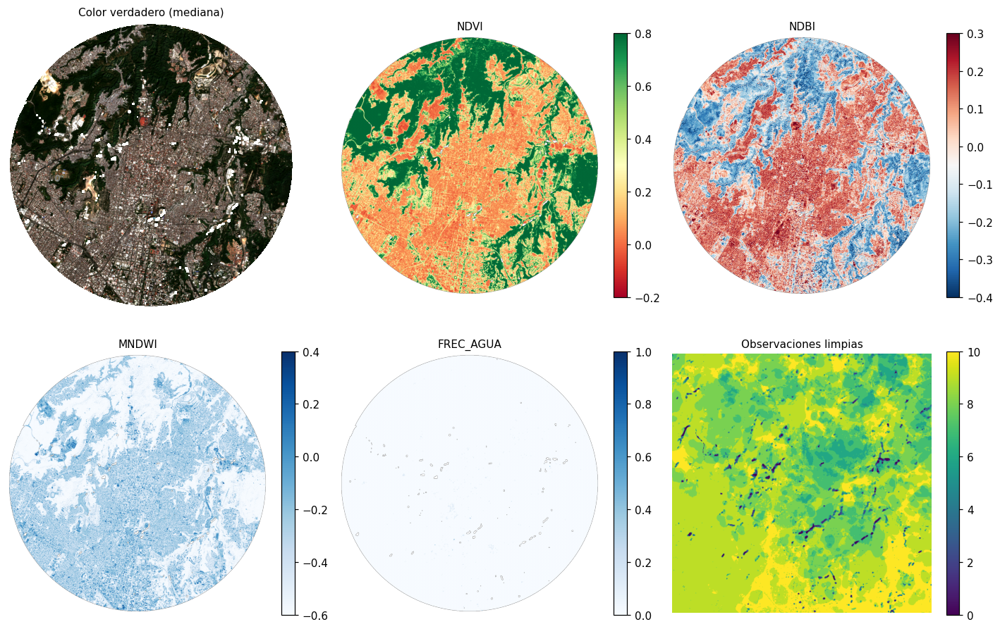

In [ ]:
b = comp
comp["ndvi"] = (b.nir - b.red) / (b.nir + b.red)
comp["ndbi"] = (b.swir16 - b.nir) / (b.swir16 + b.nir)
comp["mndwi"] = (b.green - b.swir16) / (b.green + b.swir16)
comp["bsi"] = ((b.swir16 + b.red) - (b.nir + b.blue)) / ((b.swir16 + b.red) + (b.nir + b.blue))

VARIABLES = BANDAS + ["ndvi", "ndbi", "mndwi", "bsi", "frec_agua", "mndwi_max"]

def rgb(c, p=(2, 98)):
    arr = np.dstack([c.red.values, c.green.values, c.blue.values])
    lo, hi = np.nanpercentile(arr, p)
    return np.clip((arr - lo) / (hi - lo), 0, 1)

fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
ax[0, 0].imshow(rgb(comp)); ax[0, 0].set_title("Color verdadero (mediana)")
for a, (v, cmap, lim) in zip(ax.flat[1:], [
        ("ndvi", "RdYlGn", (-0.2, 0.8)), ("ndbi", "RdBu_r", (-0.4, 0.3)),
        ("mndwi", "Blues", (-0.6, 0.4)), ("frec_agua", "Blues", (0, 1))]):
    im = a.imshow(comp[v], cmap=cmap, vmin=lim[0], vmax=lim[1]); a.set_title(v.upper())
    plt.colorbar(im, ax=a, fraction=0.046)
im = ax[1, 2].imshow(n_obs, cmap="viridis"); ax[1, 2].set_title("Observaciones limpias")
plt.colorbar(im, ax=ax[1, 2], fraction=0.046)
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

## 6. Etiquetas automáticas a partir de edificios y calles

No tenemos muestras de campo, así que **generamos las etiquetas** con capas ya mapeadas de **Overture Maps**:

- **Edificios:** polígonos de techos (Google Open Buildings, Microsoft y OpenStreetMap).
- **Calles:** ejes viales de OpenStreetMap. Cada eje se convierte en un polígono con un **ancho aproximado según su categoría** (una calle residencial ≈ 8 m, una vía primaria ≈ 14 m). Se excluyen senderos, caminos de tierra (`track`) y aceras, que no son superficie construida.

¿Por qué las calles? Si solo usamos techos, el modelo aprende que "construido = techo" y deja fuera el pavimento, aunque las calles forman parte de la **mancha urbana**.

Reglas de etiquetado para cada píxel de 10 m (las fracciones se calculan rasterizando a 2 m):

| Etiqueta | Regla |
|---|---|
| **Construido – techos** | fracción de techos ≥ `UMBRAL_TECHOS` |
| **Construido – calles** | fracción de techos + calles ≥ `UMBRAL_CALLES`, hay calle en el píxel **y** algún edificio a menos de `DISTANCIA_URBANA_M`. Así las carreteras que cruzan bosque o potreros **no** se etiquetan como ciudad. |
| **No construido** | ningún edificio ni calle en el píxel ni en sus 8 vecinos |
| *Sin etiqueta* | todo lo demás (bordes y mezclas ambiguas) |

> ⚠️ Estas etiquetas tienen errores: edificios faltantes, calles sin categoría o con un ancho distinto al supuesto. El Random Forest tolera bastante ese ruido. Puedes ajustar los anchos en el diccionario `ANCHO_VIA`.

In [ ]:
USAR_CALLES = True #@param {type:"boolean"}

from overturemaps import core as overture

def descargar_overture(tipo):
    gdf = overture.geodataframe(tipo, bbox=BBOX)
    if gdf.crs is None:            # Overture entrega lon/lat sin declarar el CRS
        gdf = gdf.set_crs("EPSG:4326")
    return gdf

print("Descargando edificios de Overture Maps…")
edificios = descargar_overture("building")
if edificios.empty:
    raise RuntimeError("Overture no tiene edificios en esta zona; prueba con otra ciudad.")
edificios = edificios[edificios.geometry.type.isin(["Polygon", "MultiPolygon"])].to_crs(EPSG)
# Overture se consulta con el rectángulo BBOX; dejamos solo lo que cae dentro de la zona
# o a menos de 250 m de su borde (ese margen se usa para el contexto urbano de las calles)
zona_margen = zona.to_crs(EPSG).buffer(250).iloc[0]
edificios = edificios[edificios.intersects(zona_margen)]

def fuente(s):
    try:
        return s[0]["dataset"]
    except Exception:
        return "desconocida"
print(f"{len(edificios):,} edificios. Fuentes:")
print(edificios["sources"].apply(fuente).value_counts().to_string())

# Ancho total aproximado (m) por categoría de vía; ajústalo a tu ciudad
ANCHO_VIA = {"motorway": 20, "trunk": 16, "primary": 14, "secondary": 12, "tertiary": 10,
             "residential": 8, "unclassified": 7, "living_street": 6, "service": 5}

calles = gpd.GeoDataFrame(geometry=[], crs=EPSG)
if USAR_CALLES:
    print("\nDescargando calles de Overture Maps…")
    seg = descargar_overture("segment")
    if {"subtype", "class"}.issubset(seg.columns):
        seg = seg[(seg["subtype"] == "road") & seg["class"].isin(list(ANCHO_VIA))].to_crs(EPSG)
        seg = seg[seg.intersects(zona_margen)]
        calles = gpd.GeoDataFrame({"clase": seg["class"].values,
                                   "ancho_m": seg["class"].map(ANCHO_VIA).values},
                                  geometry=seg.geometry.values, crs=EPSG)
        km = calles.length.groupby(calles["clase"]).sum() / 1000
        calles["geometry"] = calles.buffer(calles["ancho_m"] / 2, cap_style="flat")
        print(f"{len(calles):,} tramos de calle ({km.sum():.0f} km). Km por categoría:")
        print(km.sort_values(ascending=False).round(1).to_string())
    else:
        print("⚠️ La capa de calles no trae las columnas esperadas; se sigue solo con techos.")
    if calles.empty:
        print("⚠️ No hay calles utilizables en la zona; se sigue solo con techos.")

Descargando edificios de Overture Maps…
138,467 edificios. Fuentes:
sources
Google Open Buildings     77607
Microsoft ML Buildings    55248
OpenStreetMap              5612

Descargando calles de Overture Maps…
21,030 tramos de calle (1638 km). Km por categoría:
clase
residential      799.2
service          339.3
tertiary         161.3
primary          118.5
secondary        113.7
trunk             56.0
living_street     28.4
unclassified      21.2


Construido por techos: 149,181 px · por calles: 104,250 px · no construido: 221,022 px · sin etiqueta: 549,691 px
🧠 RAM tras las etiquetas: ████░░░░░░░░░░░░░░░░ 2.9 de 13.6 GB (21 %)


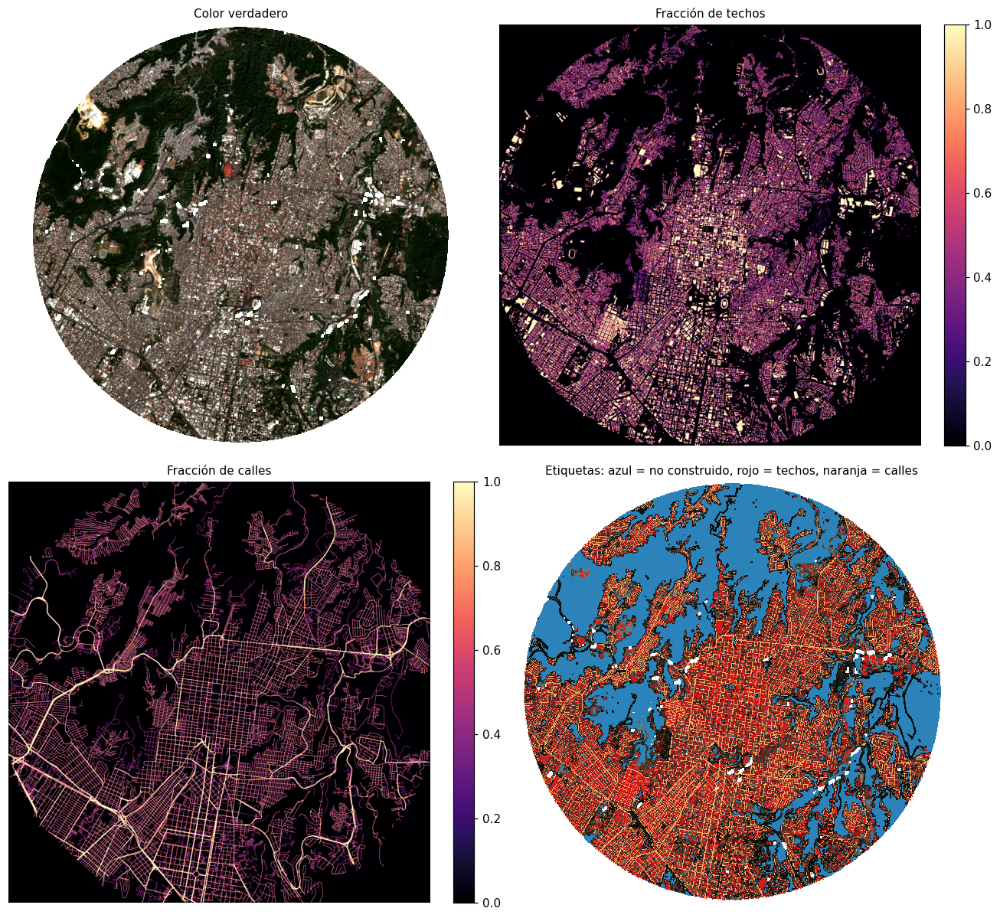

In [ ]:
UMBRAL_TECHOS = 0.5 #@param {type:"slider", min:0.2, max:0.8, step:0.05}
UMBRAL_CALLES = 0.6 #@param {type:"slider", min:0.3, max:0.9, step:0.05}
DISTANCIA_URBANA_M = 20 #@param {type:"slider", min:20, max:200, step:10}

# Grilla de 10 m del compuesto y subgrilla de 2 m
gbox = ds.odc.geobox
H, W = gbox.shape
transform = gbox.transform
F = 5
def rasterizar_fino(geoms):
    return rasterize(((g, 1) for g in geoms), out_shape=(H * F, W * F),
                     transform=transform * Affine.scale(1 / F), fill=0, dtype="uint8")
def agregar(fina):
    return fina.reshape(H, F, W, F).mean(axis=(1, 3))

fina_t = rasterizar_fino(edificios.geometry)
frac_techos = agregar(fina_t)
if len(calles):
    fina_c = rasterizar_fino(calles.geometry)
    frac_calles = agregar(fina_c)
    frac_imperm = agregar(np.maximum(fina_t, fina_c))   # techos + calles, sin contar dos veces
    del fina_c
else:
    frac_calles = np.zeros((H, W))
    frac_imperm = frac_techos
del fina_t

# Contexto urbano: algún edificio a menos de DISTANCIA_URBANA_M
r = max(1, round(DISTANCIA_URBANA_M / 10))
yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
cerca_edificio = binary_dilation(frac_techos > 0, structure=(xx**2 + yy**2) <= r**2)
hay_algo = binary_dilation((frac_techos > 0) | (frac_calles > 0), structure=np.ones((3, 3)))

# origen: 0 = no construido, 1 = techos, 2 = calles, 255 = sin etiqueta
origen = np.full((H, W), 255, dtype="uint8")
origen[~hay_algo] = 0
es_calle = (frac_imperm >= UMBRAL_CALLES) & (frac_calles > 0) & cerca_edificio
origen[es_calle] = 2
origen[frac_techos >= UMBRAL_TECHOS] = 1
origen[~valido.values] = 255
etiqueta = np.where(origen == 255, 255, (origen > 0).astype("uint8")).astype("uint8")

print(f"Construido por techos: {int((origen == 1).sum()):,} px · por calles: {int((origen == 2).sum()):,} px · "
      f"no construido: {int((origen == 0).sum()):,} px · sin etiqueta: {int((origen == 255).sum()):,} px")

ram("tras las etiquetas")

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(2, 2, figsize=(12, 11))
ax[0, 0].imshow(rgb(comp)); ax[0, 0].set_title("Color verdadero")
im = ax[0, 1].imshow(frac_techos, cmap="magma", vmin=0, vmax=1); ax[0, 1].set_title("Fracción de techos")
plt.colorbar(im, ax=ax[0, 1], fraction=0.046)
im = ax[1, 0].imshow(frac_calles, cmap="magma", vmin=0, vmax=1); ax[1, 0].set_title("Fracción de calles")
plt.colorbar(im, ax=ax[1, 0], fraction=0.046)
ax[1, 1].imshow(rgb(comp) * 0.5)
ax[1, 1].imshow(np.ma.masked_equal(origen, 255), cmap=ListedColormap(["#2b83ba", "#d7191c", "#fdae61"]),
                vmin=0, vmax=2, interpolation="nearest")
ax[1, 1].set_title("Etiquetas: azul = no construido, rojo = techos, naranja = calles")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

## 7. Entrenamiento del Random Forest

**Muestreo.** Tomamos hasta `MUESTRAS_POR_CLASE` píxeles de cada clase. Dentro de los construidos, `FRACCION_CALLES` indica qué parte sale de calles (el resto, de techos); sin esa cuota las calles quedarían en minoría. Los no construidos se reparten en **cuatro rangos de NDVI** para que el suelo desnudo y los pastos secos estén bien representados, no solo el bosque. Así el modelo aprende que "brillante" no siempre significa "techo".

**Limpieza de etiquetas (opcional).** Tras un primer entrenamiento, descartamos las muestras que el modelo contradice con mucha confianza (probabilidad *out-of-bag* de su propia clase menor que `UMBRAL_LIMPIEZA`, 0.2 por defecto) y volvemos a entrenar. Así se eliminan, por ejemplo, construcciones nuevas que todavía no aparecen en la capa de edificios. Las muestras de **calles quedan protegidas**: un primer modelo aprendido sobre todo de techos tiende a contradecirlas, y descartarlas anularía su propósito.

**Hiperparámetros del Random Forest.** Puedes cambiarlos en el formulario de la celda:

| Parámetro | Qué controla | Efecto típico |
|---|---|---|
| `N_ARBOLES` | Número de árboles del bosque | Más árboles, resultado más estable y más lento; por encima de 200–300 casi no mejora |
| `PROFUNDIDAD_MAX` | Niveles máximos de cada árbol (0 = sin límite) | Árboles poco profundos generalizan más, pero pueden quedarse cortos |
| `MIN_MUESTRAS_HOJA` | Mínimo de muestras en cada hoja final | Valores altos suavizan el modelo y lo hacen menos sensible al ruido de las etiquetas |
| `MIN_MUESTRAS_DIVISION` | Mínimo de muestras para dividir un nodo | Parecido al anterior, actúa antes en el árbol |
| `VARIABLES_POR_DIVISION` | Cuántas variables se prueban en cada división: `sqrt` (√12 ≈ 3), `log2` (≈ 3), una fracción (`0.5` = 6) o `todas` | Menos variables, árboles más distintos entre sí; con `todas` se parece a un *bagging* simple |
| `FRACCION_BOOTSTRAP` | Fracción de las muestras que ve cada árbol | Valores bajos aceleran y diversifican; 1.0 es el estándar |
| `PESO_CLASES` | `ninguno` o `balanceado` | `balanceado` compensa si una clase quedó con menos muestras |
| `UMBRAL_LIMPIEZA` | Probabilidad OOB por debajo de la cual se descarta una muestra en la limpieza | Más alto, limpieza más agresiva |

**Validación.** Reservamos un 30 % de las muestras para evaluar. Ojo: ese 30 % viene de las **mismas etiquetas automáticas**, así que la exactitud será optimista. Una validación honesta requiere puntos revisados a mano.

In [ ]:
MUESTRAS_POR_CLASE = 3000 #@param {type:"slider", min:1000, max:20000, step:1000}
FRACCION_CALLES = 0.3 #@param {type:"slider", min:0, max:0.6, step:0.05}
LIMPIAR_ETIQUETAS = True #@param {type:"boolean"}
UMBRAL_LIMPIEZA = 0.2 #@param {type:"slider", min:0.05, max:0.45, step:0.05}
#@markdown **Hiperparámetros del Random Forest:**
N_ARBOLES = 150 #@param {type:"slider", min:10, max:500, step:10}
PROFUNDIDAD_MAX = 0 #@param {type:"slider", min:0, max:40, step:1}
MIN_MUESTRAS_HOJA = 2 #@param {type:"slider", min:1, max:50, step:1}
MIN_MUESTRAS_DIVISION = 2 #@param {type:"slider", min:2, max:100, step:1}
VARIABLES_POR_DIVISION = "sqrt" #@param ["sqrt", "log2", "0.33", "0.5", "0.75", "todas"]
FRACCION_BOOTSTRAP = 1.0 #@param {type:"slider", min:0.1, max:1.0, step:0.1}
PESO_CLASES = "ninguno" #@param ["ninguno", "balanceado"]

import time
max_features = {"sqrt": "sqrt", "log2": "log2", "todas": None}.get(VARIABLES_POR_DIVISION)
if max_features is None and VARIABLES_POR_DIVISION != "todas":
    max_features = float(VARIABLES_POR_DIVISION)
HIPERPARAMETROS = dict(
    n_estimators=int(N_ARBOLES),
    max_depth=int(PROFUNDIDAD_MAX) or None,          # 0 = sin límite
    min_samples_leaf=int(MIN_MUESTRAS_HOJA),
    min_samples_split=int(MIN_MUESTRAS_DIVISION),
    max_features=max_features,
    max_samples=None if FRACCION_BOOTSTRAP >= 1 else float(FRACCION_BOOTSTRAP),
    class_weight="balanced" if PESO_CLASES == "balanceado" else None,
)
print("Hiperparámetros:", ", ".join(f"{k}={v}" for k, v in HIPERPARAMETROS.items()))

rng = np.random.default_rng(42)
X_todo = np.stack([comp[v].values for v in VARIABLES], axis=-1)  # (H, W, 12)
ndvi = comp["ndvi"].values
completo = np.isfinite(X_todo).all(axis=-1)

# Construidos: cuota de calles y el resto de techos
cand_c = np.flatnonzero((origen == 2).ravel() & completo.ravel())
cand_t = np.flatnonzero((origen == 1).ravel() & completo.ravel())
idx_c = rng.choice(cand_c, min(round(MUESTRAS_POR_CLASE * FRACCION_CALLES), len(cand_c)), replace=False)
idx_t = rng.choice(cand_t, min(MUESTRAS_POR_CLASE - len(idx_c), len(cand_t)), replace=False)
idx1 = np.concatenate([idx_c, idx_t])

idx0 = []
cortes = [-1, 0.2, 0.4, 0.6, 1.01]
for lo, hi in zip(cortes[:-1], cortes[1:]):
    cand = np.flatnonzero(((etiqueta == 0) & completo & (ndvi >= lo) & (ndvi < hi)).ravel())
    if len(cand):
        idx0.append(rng.choice(cand, min(MUESTRAS_POR_CLASE // 4, len(cand)), replace=False))
idx0 = np.concatenate(idx0)
# Si algún rango tenía pocos píxeles, completamos al azar con el resto
faltan = len(idx1) - len(idx0)
if faltan > 0:
    resto = np.setdiff1d(np.flatnonzero((etiqueta == 0).ravel() & completo.ravel()), idx0)
    idx0 = np.concatenate([idx0, rng.choice(resto, min(faltan, len(resto)), replace=False)])

idx = np.concatenate([idx1, idx0])
X = X_todo.reshape(-1, len(VARIABLES))[idx]
y = etiqueta.ravel()[idx]
print(f"Muestras: {int((y == 1).sum()):,} construidas ({len(idx_t):,} techos + {len(idx_c):,} calles) · "
      f"{int((y == 0).sum()):,} no construidas")

X_ent, X_val, y_ent, y_val, i_ent, i_val = train_test_split(
    X, y, idx, test_size=0.3, stratify=y, random_state=42)

def entrenar(X, y):
    rf = RandomForestClassifier(**HIPERPARAMETROS, oob_score=True, n_jobs=-1, random_state=42)
    t0 = time.time()
    rf.fit(X, y)
    prof = [e.get_depth() for e in rf.estimators_]
    print(f"   {len(rf.estimators_)} árboles en {time.time() - t0:.1f} s · "
          f"profundidad media {np.mean(prof):.0f} (máx. {max(prof)})")
    return rf

rf = entrenar(X_ent, y_ent)
print(f"Exactitud OOB (1.ª pasada): {rf.oob_score_:.3f}")

if LIMPIAR_ETIQUETAS:
    p_propia = rf.oob_decision_function_[np.arange(len(y_ent)), y_ent]
    o_ent = origen.ravel()[i_ent]
    conservar = (p_propia >= UMBRAL_LIMPIEZA) | (o_ent == 2)      # las calles no se descartan
    print(f"Descartadas por contradicción: {int((~conservar).sum())} "
          f"({int((~conservar & (o_ent == 1)).sum())} de techos, "
          f"{int((~conservar & (o_ent == 0)).sum())} no construidas)")
    descartadas = i_ent[~conservar]
    X_ent, y_ent = X_ent[conservar], y_ent[conservar]
    rf = entrenar(X_ent, y_ent)
    print(f"Exactitud OOB (2.ª pasada): {rf.oob_score_:.3f}")
else:
    descartadas = np.array([], dtype=int)

Hiperparámetros: n_estimators=150, max_depth=None, min_samples_leaf=2, min_samples_split=2, max_features=sqrt, max_samples=None, class_weight=None
Muestras: 3,000 construidas (2,100 techos + 900 calles) · 3,000 no construidas
   150 árboles en 2.7 s · profundidad media 18 (máx. 22)
Exactitud OOB (1.ª pasada): 0.895
Descartadas por contradicción: 119 (34 de techos, 85 no construidas)
   150 árboles en 2.2 s · profundidad media 15 (máx. 20)
Exactitud OOB (2.ª pasada): 0.918


Exactitud en el 30 % reservado: 0.907
  Aciertos en píxeles de techos: 0.923  (n = 648)
  Aciertos en píxeles de calles: 0.897  (n = 252)
  Aciertos en píxeles de no construido: 0.898  (n = 900)

               precision    recall  f1-score   support

No construido      0.914     0.898     0.906       900
   Construido      0.900     0.916     0.907       900

     accuracy                          0.907      1800
    macro avg      0.907     0.907     0.907      1800
 weighted avg      0.907     0.907     0.907      1800



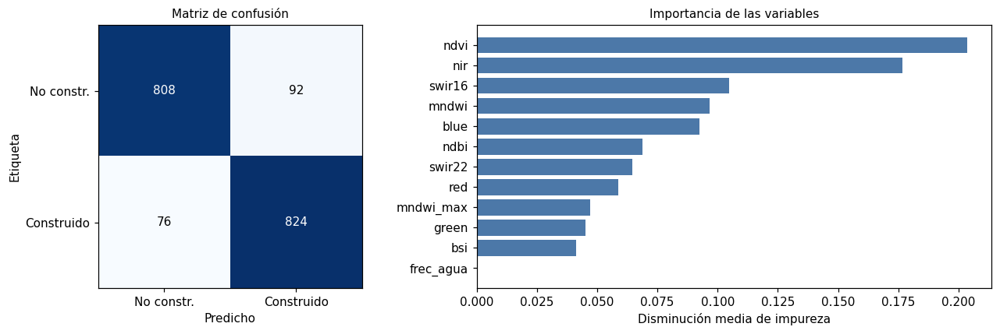

In [ ]:
pred_val = rf.predict(X_val)
print(f"Exactitud en el 30 % reservado: {accuracy_score(y_val, pred_val):.3f}")
o_val = origen.ravel()[i_val]
for cod, nombre in [(1, "techos"), (2, "calles"), (0, "no construido")]:
    sel = o_val == cod
    if sel.any():
        print(f"  Aciertos en píxeles de {nombre}: {(pred_val[sel] == y_val[sel]).mean():.3f}  (n = {int(sel.sum()):,})")
print()
print(classification_report(y_val, pred_val, target_names=["No construido", "Construido"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})
cm = confusion_matrix(y_val, pred_val)
ax[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[0].text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax[0].set_xticks([0, 1], ["No constr.", "Construido"]); ax[0].set_yticks([0, 1], ["No constr.", "Construido"])
ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Etiqueta"); ax[0].set_title("Matriz de confusión")

imp = pd.Series(rf.feature_importances_, index=VARIABLES).sort_values()
ax[1].barh(imp.index, imp.values, color="#4c78a8")
ax[1].set_title("Importancia de las variables"); ax[1].set_xlabel("Disminución media de impureza")
plt.tight_layout(); plt.show()

**Pregunta para la discusión:** ¿qué variables pesan más? Si dominan el azul, el verde y el rojo, el modelo se guía sobre todo por el **brillo**, y es probable que confunda suelo desnudo con techos. Si pesan el NDBI, el SWIR o la frecuencia de agua, está aprovechando información que el ojo no ve.

## 8. Predicción en toda la zona

El modelo asigna a cada píxel una **probabilidad de ser construido** (urbano), que se muestra de **verde** (0, no urbano) a **rojo** (1, urbano). Para obtener un mapa binario usamos un umbral (`UMBRAL`): subirlo reduce falsos positivos pero aumenta omisiones.

🧠 RAM tras la predicción: █████░░░░░░░░░░░░░░░ 3.1 de 13.6 GB (23 %)


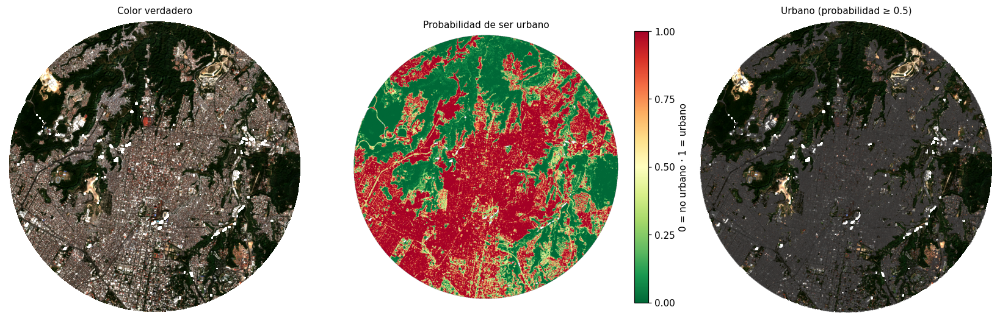

In [ ]:
UMBRAL = 0.5 #@param {type:"slider", min:0.1, max:0.9, step:0.05}

X_flat = X_todo.reshape(-1, len(VARIABLES))
ok = completo.ravel()
prob = np.full(H * W, np.nan, dtype="float32")
filas = np.flatnonzero(ok)
for i in range(0, len(filas), 500_000):
    lote = filas[i:i + 500_000]
    prob[lote] = rf.predict_proba(X_flat[lote])[:, 1]
prob = prob.reshape(H, W)
ram("tras la predicción")
construido = np.where(np.isfinite(prob), (prob >= UMBRAL).astype("uint8"), 255).astype("uint8")

fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))
ax[0].imshow(rgb(comp)); ax[0].set_title("Color verdadero")
COLOR_URBANO = "#333333"     # gris oscuro para el área clasificada como urbana
im = ax[1].imshow(prob, cmap="RdYlGn_r", vmin=0, vmax=1); ax[1].set_title("Probabilidad de ser urbano")
cb = plt.colorbar(im, ax=ax[1], fraction=0.046)
cb.set_label("0 = no urbano · 1 = urbano"); cb.set_ticks([0, 0.25, 0.5, 0.75, 1])
ax[2].imshow(rgb(comp))
ax[2].imshow(np.ma.masked_not_equal(construido, 1), cmap=ListedColormap([COLOR_URBANO]), alpha=0.85)
ax[2].set_title(f"Urbano (probabilidad ≥ {UMBRAL})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 9. Mapa interactivo para revisar el resultado

Activa y desactiva capas con el control de la esquina superior derecha. El área **urbana** aparece en **gris oscuro**; la capa de **probabilidad** va de **verde** (no urbano) a **rojo** (urbano), con su escala arriba a la derecha y una leyenda abajo a la izquierda. Compara la clasificación con la imagen de alta resolución de Esri: **¿dónde se equivoca el modelo?** Fíjate en orillas de embalses, laderas sin vegetación, canchas de tierra y zonas de construcción.


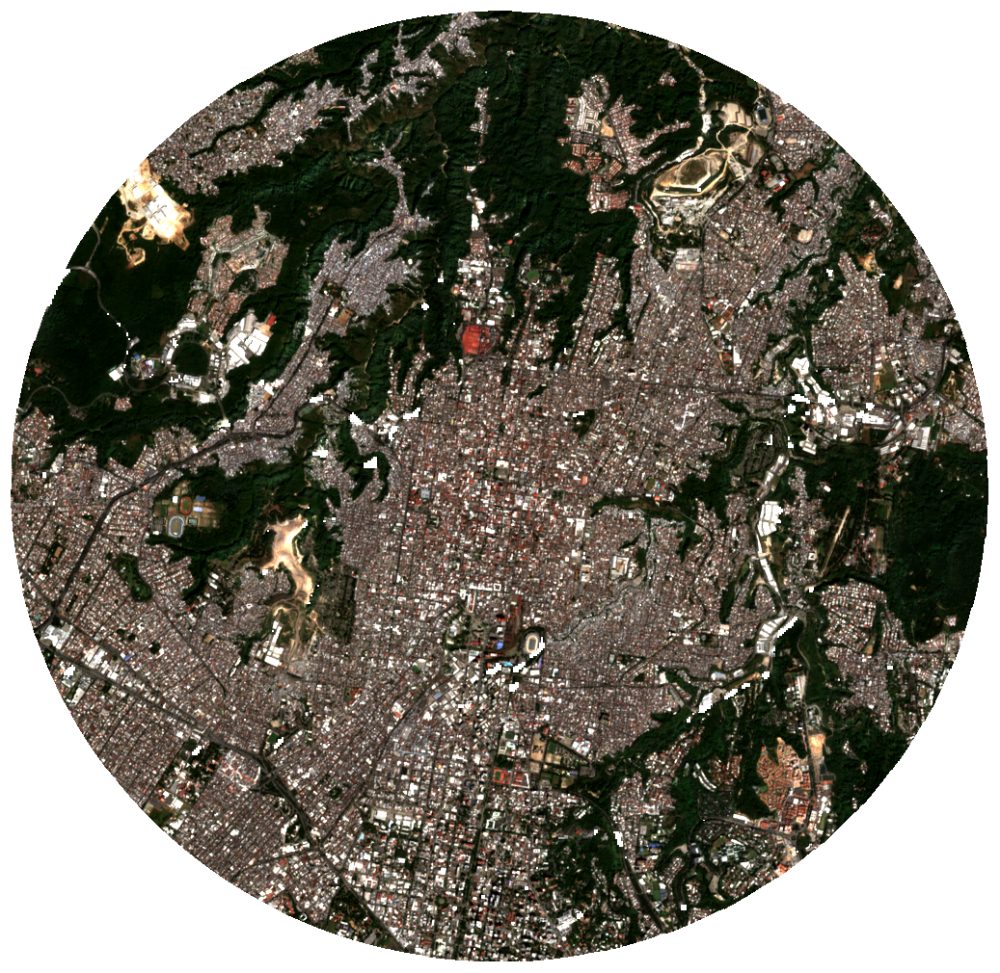
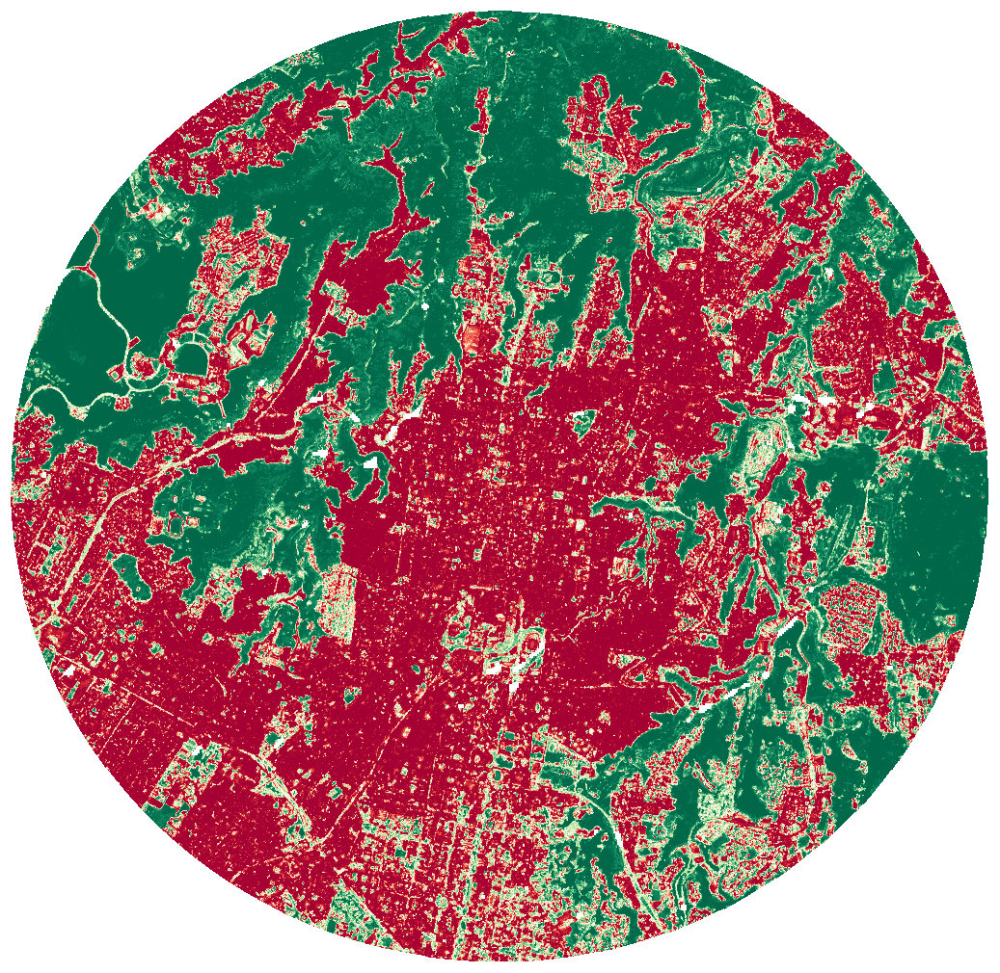
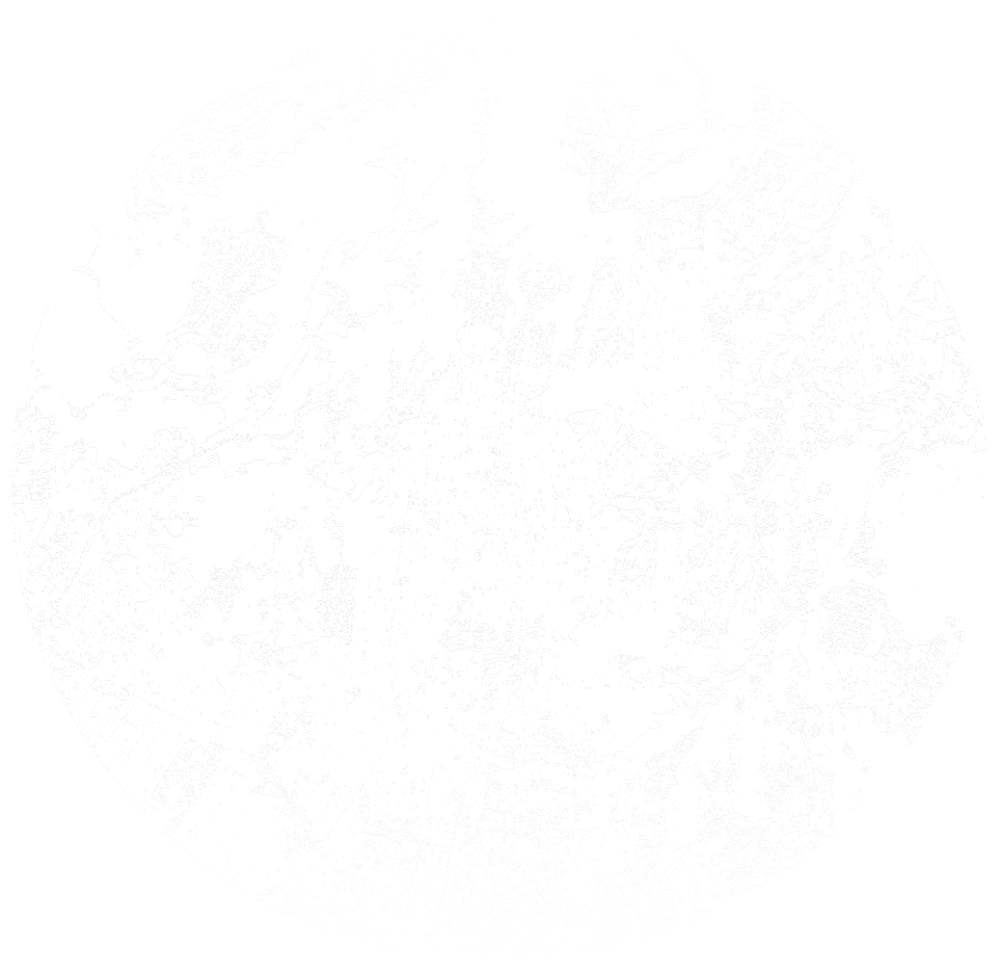

In [ ]:
def a_4326(arr, nombre, nodata):
    da = xr.DataArray(arr, dims=("y", "x"), coords={"y": ds.y, "x": ds.x}, name=nombre)
    da = da.rio.write_crs(EPSG).rio.write_nodata(nodata)
    return da.rio.reproject("EPSG:4326")

def bounds(da):
    x0, y0, x1, y1 = da.rio.bounds()
    return [[y0, x0], [y1, x1]]

# Capa de color verdadero
img = rgb(comp)
canales = [a_4326(np.where(np.isfinite(img[..., k]), img[..., k], np.nan).astype("float32"), "c", np.nan)
           for k in range(3)]
rgba_rgb = np.dstack([np.nan_to_num(c.values) for c in canales] +
                     [np.isfinite(canales[0].values).astype(float)])

# Capas de probabilidad y construido
p4 = a_4326(prob, "prob", np.nan)
cmap = plt.get_cmap("RdYlGn_r")      # verde = no urbano, rojo = urbano
rgba_prob = cmap(np.nan_to_num(p4.values))
rgba_prob[..., 3] = np.where(np.isfinite(p4.values), 0.75, 0)

c4 = a_4326(construido, "construido", 255)
rgba_c = np.zeros(c4.shape + (4,))
rgba_c[c4.values == 1] = [0.2, 0.2, 0.2, 0.85]     # gris oscuro

m = folium.Map(location=[lat_c, lon_c], zoom_start=13, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Imagen alta resolución (Esri)").add_to(m)
folium.raster_layers.ImageOverlay(rgba_rgb, bounds(p4), name="Sentinel-2 mediana", show=False,
                                  mercator_project=True).add_to(m)
folium.raster_layers.ImageOverlay(rgba_prob, bounds(p4), name="Probabilidad de ser urbano", show=False,
                                  mercator_project=True).add_to(m)
folium.raster_layers.ImageOverlay(rgba_c, bounds(c4), name=f"Urbano (≥ {UMBRAL})",
                                  mercator_project=True).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

# Leyendas: escala continua de probabilidad y clase urbana
import branca.colormap as bcm
from matplotlib.colors import to_hex
escala = bcm.LinearColormap([to_hex(cmap(v)) for v in np.linspace(0, 1, 11)], vmin=0, vmax=1,
                            caption="Probabilidad de ser urbano (0 = no urbano, 1 = urbano)")
escala.add_to(m)
leyenda = f"""
<div style="position: fixed; bottom: 28px; left: 12px; z-index: 9999; background: rgba(255,255,255,0.92);
            padding: 8px 10px; border-radius: 6px; font: 12px/1.5 Arial, sans-serif; color: #222;
            box-shadow: 0 1px 4px rgba(0,0,0,0.3);">
  <b>Clasificación</b><br>
  <span style="display:inline-block; width:14px; height:14px; background:#333333; vertical-align:middle;
               margin-right:6px; border:1px solid #000;"></span>Urbano (probabilidad ≥ {UMBRAL})<br>
  <span style="display:inline-block; width:14px; height:14px; vertical-align:middle; margin-right:6px;
               background:linear-gradient(to right, {to_hex(cmap(0.0))}, {to_hex(cmap(0.5))}, {to_hex(cmap(1.0))});
               border:1px solid #999;"></span>Probabilidad: verde = no urbano → rojo = urbano
</div>"""
m.get_root().html.add_child(folium.Element(leyenda))
m

## 10. Resumen de superficies

Cada píxel mide 10 × 10 m = 100 m² = 0.01 ha. Comparamos el área clasificada como construida con:
- la **huella de techos** de Overture (solo los techos),
- la **superficie de calles** estimada con los anchos de `ANCHO_VIA`, y
- la superficie de techos + calles, que es una referencia aproximada de lo impermeable.

La curva muestra cuánto cambia la superficie construida según el umbral. Una curva **plana** en torno a 0.5 indica un modelo seguro de sí mismo; una curva **inclinada** indica muchos píxeles dudosos.

,indicador,valor
0,Área analizada (ha),7821.7
1,"Construido, umbral 0.5 (ha)",4174.7
2,% de la zona,53.4
3,Techos según Overture (ha),1632.4
4,Calles según Overture (ha),1151.6
5,Techos + calles (ha),2744.1


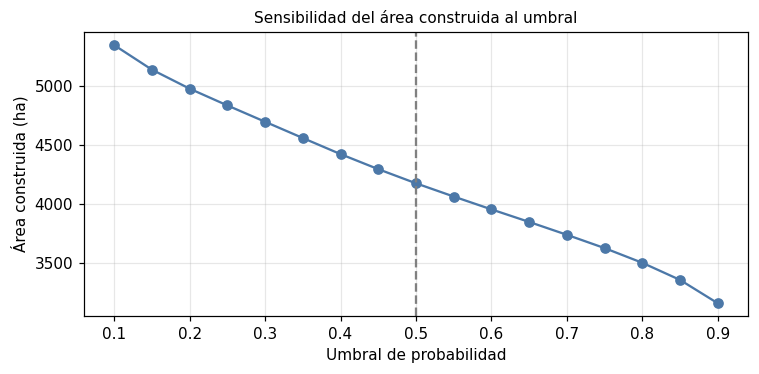

In [ ]:
ha_px = 0.01
area_valida = int(np.isfinite(prob).sum()) * ha_px
area_constr = int((construido == 1).sum()) * ha_px
dentro_zona = np.isfinite(prob)
area_techos = float(frac_techos[dentro_zona].sum()) * ha_px
area_calles = float(frac_calles[dentro_zona].sum()) * ha_px
area_imperm = float(frac_imperm[dentro_zona].sum()) * ha_px

resumen = pd.DataFrame({
    "indicador": ["Área analizada (ha)", f"Construido, umbral {UMBRAL} (ha)", "% de la zona",
                  "Techos según Overture (ha)", "Calles según Overture (ha)", "Techos + calles (ha)"],
    "valor": [area_valida, area_constr, 100 * area_constr / area_valida,
              area_techos, area_calles, area_imperm],
}).round(1)
display(resumen)

umbrales = np.round(np.arange(0.1, 0.91, 0.05), 2)
areas = [np.nansum(prob >= u) * ha_px for u in umbrales]
plt.figure(figsize=(7, 3.5))
plt.plot(umbrales, areas, marker="o", color="#4c78a8")
plt.axvline(UMBRAL, ls="--", color="grey")
plt.xlabel("Umbral de probabilidad"); plt.ylabel("Área construida (ha)")
plt.title("Sensibilidad del área construida al umbral"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 11. Descarga de resultados

El primer zip contiene los resultados (GeoTIFF en UTM a 10 m, listos para QGIS):
- `probabilidad.tif`: probabilidad de construido (0–1).
- `construido.tif`: 1 = construido, 0 = no construido, 255 = sin dato.
- `etiquetas.tif`: 0 = no construido, 1 = construido por techos, 2 = construido por calles, 255 = sin etiqueta.
- `edificios_overture.gpkg` y `calles_overture.gpkg`: capas de referencia (las calles ya con su ancho).
- `muestras_entrenamiento.csv`: cada muestra con sus coordenadas, clase, origen, si se descartó y sus 12 variables.
- `zona_estudio.gpkg`: el círculo de la zona analizada.
- `resumen.csv` y `hiperparametros.csv` (la configuración del modelo, para comparar corridas).

In [ ]:
import os, shutil
nombre = "_".join(_normalizar(CIUDAD).replace("(", " ").replace(")", " ").split())
salida = f"/content/resultados_{nombre}"
os.makedirs(salida, exist_ok=True)

def guardar(arr, archivo, nodata, dtype):
    da = xr.DataArray(arr.astype(dtype), dims=("y", "x"), coords={"y": ds.y, "x": ds.x})
    da.rio.write_crs(EPSG).rio.write_nodata(nodata).rio.to_raster(
        f"{salida}/{archivo}", compress="deflate")

guardar(prob, "probabilidad.tif", np.nan, "float32")
guardar(construido, "construido.tif", 255, "uint8")
guardar(origen, "etiquetas.tif", 255, "uint8")
edificios[["geometry"]].to_file(f"{salida}/edificios_overture.gpkg", driver="GPKG")
if len(calles):
    calles.to_file(f"{salida}/calles_overture.gpkg", driver="GPKG")
zona.to_file(f"{salida}/zona_estudio.gpkg", driver="GPKG")
resumen.to_csv(f"{salida}/resumen.csv", index=False)
config = {**HIPERPARAMETROS, "oob_score": round(rf.oob_score_, 4), "radio_km": RADIO_KM,
          "fechas": f"{FECHA_INICIO}/{FECHA_FIN}", "max_fechas": MAX_FECHAS}
pd.Series({k: "sin límite / no" if v is None else str(v) for k, v in config.items()},
          name="valor").to_csv(f"{salida}/hiperparametros.csv", index_label="parametro")

# Tabla de muestras de entrenamiento
fila, col = np.unravel_index(idx, (H, W))
xs, ys = transform * (col + 0.5, fila + 0.5)
muestras = pd.DataFrame({"x": xs, "y": ys, "clase": y,
                         "origen": pd.Series(origen.ravel()[idx]).map({0: "no construido", 1: "techos", 2: "calles"}),
                         "uso": np.where(np.isin(idx, i_val), "validacion", "entrenamiento"),
                         "descartada": np.isin(idx, descartadas)})
muestras = pd.concat([muestras, pd.DataFrame(X, columns=VARIABLES)], axis=1)
muestras.to_csv(f"{salida}/muestras_entrenamiento.csv", index=False)

zip_path = shutil.make_archive(salida, "zip", salida)
print("Archivos:", sorted(os.listdir(salida)))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print(f"Fuera de Colab: el zip está en {zip_path}")

Archivos: ['calles_overture.gpkg', 'construido.tif', 'edificios_overture.gpkg', 'etiquetas.tif', 'hiperparametros.csv', 'muestras_entrenamiento.csv', 'probabilidad.tif', 'resumen.csv', 'zona_estudio.gpkg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Bloque completo de variables predictoras

Un solo GeoTIFF **multibanda** con las 12 variables que usa el modelo, en el mismo orden, con el nombre de cada banda en sus metadatos. Sirve para entrenar otros modelos en QGIS, R o Python con tus propias muestras.

| Banda | Variable | Banda | Variable |
|---|---|---|---|
| 1 | blue | 7 | ndvi |
| 2 | green | 8 | ndbi |
| 3 | red | 9 | mndwi |
| 4 | nir | 10 | bsi |
| 5 | swir16 | 11 | frec_agua |
| 6 | swir22 | 12 | mndwi_max |

Las bandas 1–6 son reflectancia de superficie (0–1) de la mediana; fuera del círculo el valor es *NoData*. Pesa unos 50 MB por cada 100 km² (unos 100 MB con 8 km de radio), así que se descarga aparte.

In [ ]:
pila = comp[VARIABLES].to_array("banda").astype("float32")
pila.attrs["long_name"] = tuple(VARIABLES)          # nombres de banda en el GeoTIFF
archivo_pila = f"/content/variables_predictoras_{nombre}.tif"   # fuera del zip de resultados
(pila.rio.write_crs(EPSG).rio.write_nodata(np.nan)
     .rio.to_raster(archivo_pila, compress="deflate", predictor=3, tiled=True))
print(f"{archivo_pila}: {len(VARIABLES)} bandas, {os.path.getsize(archivo_pila) / 1e6:.1f} MB")
try:
    from google.colab import files
    files.download(archivo_pila)
except ImportError:
    pass

/content/variables_predictoras_ciudad_de_guatemala.tif: 12 bandas, 30.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Para seguir explorando

**Ejercicios sugeridos**
1. **Otra ciudad.** Elige otra ciudad en el paso 2 (por ejemplo San Pedro Sula, Managua, San Salvador o Santo Domingo), o busca una más pequeña en el catálogo, y vuelve a correr todo con **Entorno de ejecución → Ejecutar todas**. ¿Funciona igual de bien el modelo en una ciudad costera o muy verde?
2. **Radio mayor.** Sube el radio a 12 o 15 km y mira las líneas 🧠 RAM: ¿en qué paso crece más la memoria? ¿Qué pasa si bajas `MAX_FECHAS`?
3. **Hiperparámetros.** Compara 50, 150 y 400 árboles, o limita la profundidad a 10: ¿cambia la exactitud OOB? ¿y el tiempo de entrenamiento? ¿y el mapa?
4. **El umbral de techos.** Sube `UMBRAL_TECHOS` a 0.6: ¿cambia la importancia de las variables? ¿y la superficie construida?
5. **Sin calles.** Desactiva `USAR_CALLES` (o pon `FRACCION_CALLES` en 0) y compara cómo quedan las vías en el mapa.
6. **Sin limpieza.** Desactiva `LIMPIAR_ETIQUETAS` y compara los mapas.
7. **Temporada.** Usa solo meses de lluvia (junio–octubre): ¿cuántas fechas limpias quedan?

**Limitaciones de esta demostración**
- Las etiquetas vienen de edificios y calles que pueden estar **desactualizados** o incompletos en asentamientos informales, y el ancho de las calles es una suposición por categoría.
- La exactitud se mide contra las mismas etiquetas automáticas: es **optimista**. Para reportar resultados hace falta una muestra de validación revisada a mano.
- A 10 m, calles, patios y techos se mezclan en el mismo píxel: el resultado es una **mancha urbana**, no un inventario de edificios.

**Datos y herramientas**
- Sentinel-2 L2A Collection 1 — ESA Copernicus, vía [Earth Search](https://element84.com/earth-search/) (Element 84 / AWS)
- Ciudades — [GeoNames](https://www.geonames.org) (CC BY 4.0)
- Edificios — [Overture Maps Foundation](https://overturemaps.org) (incluye Google Open Buildings, Microsoft y OpenStreetMap), licencia ODbL / CDLA
- Librerías: `pystac-client`, `odc-stac`, `rioxarray`, `scikit-learn`, `folium`